# nb10 — Model comparison and biological interpretation

**Prepared in advance and intentionally unexecuted. Run this after nb09 finishes.**

This notebook reviews saved outputs and adds **frozen cross-cell-line treatment prediction**.
It never trains or tunes models. Transfer loads saved checkpoints and transforms raw target inputs
using source-model preprocessing. Compare nb08 MLPs, nb09 RNA-only/integrated kernels,
and both completed nb11 pathway-model versions.

Questions:
- Does integration improve AUROC, average precision and classification errors?
- Does it improve over the saved RNA and ATAC MLP baselines?
- Were the selected fits converged, and how do validation/test scores compare?
- Which pathway and motif groups were selected? How do they relate to the earlier biological findings?

No conclusions about nb09 are assumed. Tables, figures and the report are created only when you run it.

### Required inputs
The complete nb09 results directory under results/tables/nb09/RUN_ID/.
It already includes nb08 test predictions, configuration and the split handoff, so model
weights and raw inputs are unnecessary for the original review sections. The transfer section
requires full nb08/nb09/nb11 checkpoints, nb09 random-feature maps (including referenced older run
folders), nb11 structures/peak-gene links, all four nb02 H5AD files and the original results folders.
Results ZIPs alone do not contain model checkpoints. If using the nb09 results ZIP, extract its contents into
that run directory first.

### Optional biological context
Existing nb04 Hallmark GSEA, nb06 pathway summaries and nb07 motif enrichment tables.
Missing context is reported explicitly and does not stop the performance comparison.
The original review is lightweight CPU work. Frozen neural inference can use a GPU; CPU also
works. Transfer needs more RAM/time. No sequence scan or reference download is required.


## How to interpret the review

Use identical test cells, E2-positive labels and saved decision thresholds:
0.5 for MLP probabilities and 0 for group-lasso decision scores. Recompute metrics from the saved
predictions and verify them against nb09's summary before comparing models.

AUROC and average precision use continuous scores. Kernel scores are uncalibrated, so this notebook
does not compare their log loss/Brier scores with MLP probabilities. Error correction is paired by
cell; it reflects the fixed thresholds and is not a significance test.

Validation/test gaps and solver checks concern the integrated model for each cell line. nb09's portable
export does not include the MLP validation predictions, so this notebook does not invent them.

Group norms are **unsigned predictive weights**, not pathway activity, TF binding or causal effects.
Keep group-coverage exclusions and motif aliases; two names may represent the same kernel.
Cross-line overlap describes selection in two separately fitted models, not transfer performance or
repeated-split stability. Absence from a model's eligible groups is distinguished from a zero weight.

Earlier GSEA/ATAC/motif results use the same cohort and are descriptive context, not independent
validation. Both positive/negative NES and all motif directions, matching-QC flags and coordinate
scenarios are retained. Do not select the most favorable enrichment result.

These are single-split, cell-level results. Biological replicate IDs are unavailable, and
library/treatment confounding remains possible. Test results are already known; any test-guided
tuning needs independent confirmation. No confidence intervals or statistical significance claims
are produced here.


In [1]:
import importlib.util
import subprocess
import sys
packages={"numpy":"numpy","pandas":"pandas","matplotlib":"matplotlib","sklearn":"scikit-learn"}
missing=[spec for name,spec in packages.items() if importlib.util.find_spec(name) is None]
if missing:
    subprocess.check_call([sys.executable,"-m","pip","install","-q",*missing])


In [2]:
from pathlib import Path
from datetime import datetime, timezone
import os
try:
    import google.colab
    IN_COLAB=True
except ImportError:
    IN_COLAB=False
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE=Path("/content/drive/MyDrive/breast-cancer-multiome-estrogen")
else:
    here=Path.cwd()
    BASE=Path(os.environ.get("MULTIOME_PROJECT_ROOT",
              str(here.parent if here.name=="notebooks" else here)))

# Leave blank only if exactly one completed nb09 results folder exists.
# If several runs exist, set the exact folder name to review.
NB09_RUN_ID="20261012T114858_335840Z"
RUN_ID=datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
print("Project:",BASE)
print("Available nb09 folders:",[p.name for p in (BASE/"results"/"tables"/"nb09").glob("*") if p.is_dir()])


Mounted at /content/drive
Project: /content/drive/MyDrive/breast-cancer-multiome-estrogen
Available nb09 folders: ['20261012T085524_321769Z', '20261012T113759_726198Z', '20261012T114858_335840Z', '20261012T183857_562670Z', '20261012T184252_110749Z']


## Embedded review implementation
Defines functions only; no model code or fitting library is imported.

In [3]:
"""nb10: review saved predictions and group weights; no model fitting."""
from pathlib import Path
import hashlib
import json
import shutil
import sys
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score,
    balanced_accuracy_score, f1_score, confusion_matrix, roc_curve, precision_recall_curve)

LINES=("MCF7","T47D")
MODES=("RNA_ATAC","RNA")

def sha256(path):
    h=hashlib.sha256()
    with Path(path).open("rb") as f:
        for chunk in iter(lambda:f.read(1024*1024),b""):
            h.update(chunk)
    return h.hexdigest()

def json_save(path,value):
    Path(path).write_text(json.dumps(value,indent=2,allow_nan=False)+"\n")

def read_file(path,inputs,sep=","):
    path=Path(path)
    inputs.append({"path":str(path),"sha256":sha256(path),"bytes":path.stat().st_size})
    if path.suffix==".json":
        return json.loads(path.read_text())
    return pd.read_csv(path,sep=sep)

def as_bool(series):
    mapping={"true":True,"false":False,"1":True,"0":False}
    text=series.astype(str).str.lower()
    if not text.isin(mapping).all():
        raise ValueError(f"Invalid boolean values in {series.name}.")
    return text.map(mapping)

def choose_run(base,run_id):
    root=Path(base)/"results"/"tables"/"nb09"
    if run_id:
        chosen=root/run_id
    else:
        candidates=sorted(p for p in root.glob("*") if (p/"metrics_comparison.csv").is_file())
        if len(candidates)!=1:
            names=[p.name for p in candidates]
            raise ValueError(f"Set NB09_RUN_ID to one completed run. Found: {names}. "
                             "Wait for nb09 to finish or extract its results ZIP into its run folder.")
        chosen=candidates[0]
    required=["config.json","nb08_config.json","nb08_handoff.json","metrics_comparison.csv"]
    for line in LINES:
        required.append(f"{line}_splits.csv")
        for mode in MODES:
            required.extend(f"{line}_{mode}_{suffix}" for suffix in
                ("metrics.json","validation_search.csv","validation_predictions.csv",
                 "test_predictions.csv","group_weights.csv"))
        for mode in ("RNA","ATAC"):
            required.extend([f"nb08_{line}_{mode}_predictions.csv",
                             f"{line}_{mode}_group_coverage.csv"])
    missing=[name for name in required if not (chosen/name).is_file()]
    if missing:
        raise FileNotFoundError("nb09 results incomplete:\n"+"\n".join(missing))
    return chosen

def prepare_review(base,run_id,nb09_run_id):
    source=choose_run(base,nb09_run_id)
    out=Path(base)/"results"/"tables"/"nb10"/run_id
    if out.exists():
        raise FileExistsError("Choose a new RUN_ID; existing review will not be overwritten.")
    out.mkdir(parents=True)
    inputs=[]
    handoff=read_file(source/"nb08_handoff.json",inputs)
    if handoff["positive_class"]!="E2":
        raise ValueError("Unexpected positive class.")
    config=read_file(source/"config.json",inputs)
    baseline=read_file(source/"nb08_config.json",inputs)
    json_save(out/"review_config.json",{
        "nb09_run_id":source.name,"nb08_run_id":handoff["run_id"],
        "nb08_learning_rate":baseline["learning_rate"],"nb09_config":config,
        "positive_class":"E2","confidence_intervals":"not estimated",
        "scope":"Saved-output kernel-model review plus separately configured frozen cross-line inference. No fitting or tuning."})
    json_save(out/"environment.json",{"python":sys.version,
        "packages":{p:importlib.metadata.version(p) for p in
                    ("numpy","pandas","matplotlib","scikit-learn")}})
    print("Reviewing nb09:",source.name)
    print("nb08 run:",handoff["run_id"],"; learning rate:",baseline["learning_rate"])
    return source,out,inputs,handoff

def prediction_frame(path,expected,inputs,score_column,threshold):
    p=read_file(path,inputs)
    required={"cell_id","label_E2",score_column,"predicted_label_E2"}
    if not required.issubset(p.columns) or not p.cell_id.is_unique:
        raise ValueError(f"Invalid prediction table: {path}")
    p["cell_id"]=p.cell_id.astype(str)
    if not set(p.cell_id)==set(expected.cell_id):
        raise ValueError(f"Missing/extra test or validation cells: {path}")
    p=p.set_index("cell_id").loc[expected.cell_id].reset_index()
    if not np.array_equal(p.label_E2.to_numpy(),expected.label_E2.to_numpy()):
        raise ValueError(f"Label mismatch: {path}")
    score=p[score_column].to_numpy(dtype=float)
    if not np.isfinite(score).all():
        raise ValueError("Nonfinite predictions.")
    if score_column=="probability_E2" and ((score<0)|(score>1)).any():
        raise ValueError("MLP probabilities outside [0,1].")
    predicted=(score>=threshold).astype(int)
    if not np.array_equal(predicted,p.predicted_label_E2):
        raise ValueError("Saved classification differs from its stated threshold.")
    p["score"]=score
    p["predicted"]=predicted
    return p

def calculate_metrics(p):
    y=p.label_E2.to_numpy()
    if set(y)!={0,1}:
        raise ValueError("Both classes required.")
    tn,fp,fn,tp=confusion_matrix(y,p.predicted,labels=[0,1]).ravel()
    return {"n_cells":len(p),"E2_prevalence":float(y.mean()),
        "AUROC":float(roc_auc_score(y,p.score)),
        "average_precision":float(average_precision_score(y,p.score)),
        "accuracy":float(accuracy_score(y,p.predicted)),
        "balanced_accuracy":float(balanced_accuracy_score(y,p.predicted)),
        "F1_E2":float(f1_score(y,p.predicted,zero_division=0)),
        "TN":int(tn),"FP":int(fp),"FN":int(fn),"TP":int(tp),"errors":int(fp+fn)}

def review_predictions(source,out,inputs,handoff):
    saved=read_file(source/"metrics_comparison.csv",inputs)
    predictions,gaps,solver_rows,split_counts={},[],[],[]
    metric_rows=[]
    for line in LINES:
        path=source/f"{line}_splits.csv"
        if sha256(path)!=handoff["manifests"][line]["sha256"]:
            raise ValueError("Split hash differs from nb08 handoff.")
        m=read_file(path,inputs)
        m["cell_id"]=m.cell_id.astype(str)
        if not m.cell_id.is_unique or set(m["split"])!={"train","validation","test"}:
            raise ValueError("Invalid split manifest.")
        if set(m.cell_line)!={line} or not np.array_equal(m.label_E2,(m.treatment=="E2").astype(int)):
            raise ValueError("Invalid split labels.")
        expected=m.loc[m["split"]=="test",["cell_id","label_E2"]].reset_index(drop=True)
        val=m.loc[m["split"]=="validation",["cell_id","label_E2"]].reset_index(drop=True)
        split_counts.append(m.groupby(["cell_line","split","treatment"]).size().rename("cells").reset_index())
        specifications=[("MLP_nb08",mode,f"nb08_{line}_{mode}_predictions.csv","probability_E2",.5)
                        for mode in ("RNA","ATAC")]
        specifications += [("scMKL_style",mode,f"{line}_{mode}_test_predictions.csv","decision_score_E2",0)
                           for mode in MODES]
        for family,mode,filename,column,threshold in specifications:
            p=prediction_frame(source/filename,expected,inputs,column,threshold)
            met=calculate_metrics(p)
            previous=saved[(saved.cell_line==line)&(saved.model==family)&(saved.modality==mode)]
            if len(previous)!=1:
                raise ValueError("Missing/duplicate model in nb09 summary.")
            for key in ("AUROC","average_precision","accuracy","balanced_accuracy","F1_E2"):
                if not np.isclose(met[key],float(previous.iloc[0][key]),atol=1e-7,rtol=0):
                    raise ValueError(f"Saved metric mismatch: {line} {family} {mode} {key}")
            predictions[(line,family,mode)]=p
            metric_rows.append({"cell_line":line,"model":family,"modality":mode,**met})
            if family=="scMKL_style":
                meta=read_file(source/f"{line}_{mode}_metrics.json",inputs)
                vp=prediction_frame(source/f"{line}_{mode}_validation_predictions.csv",val,inputs,column,0)
                vm=calculate_metrics(vp)
                if not np.isclose(vm["AUROC"],meta["validation_AUROC"],atol=1e-7,rtol=0):
                    raise ValueError("Validation AUROC mismatch.")
                search=read_file(source/f"{line}_{mode}_validation_search.csv",inputs)
                search["converged"]=as_bool(search.converged)
                selected=search[np.isclose(search.alpha_ratio,meta["selected_alpha_ratio"])]
                if len(selected)!=1 or not selected.iloc[0]["converged"]:
                    raise ValueError("Selected model was not a unique converged candidate.")
                if not np.isclose(selected.iloc[0]["validation_AUROC"],vm["AUROC"],atol=1e-7,rtol=0):
                    raise ValueError("Selected candidate/validation predictions disagree.")
                winner=search[search.converged].sort_values(
                    ["validation_AUROC","validation_average_precision","selected_groups","alpha_ratio"],
                    ascending=[False,False,True,False]).iloc[0]
                if not np.isclose(winner.alpha_ratio,meta["selected_alpha_ratio"]):
                    raise ValueError("Selected model does not match the recorded validation selection rule.")
                for _,candidate in search.iterrows():
                    solver_rows.append({"cell_line":line,"modality":mode,**candidate.to_dict(),
                        "chosen":bool(np.isclose(candidate.alpha_ratio,meta["selected_alpha_ratio"]))})
                gaps.append({"cell_line":line,"modality":mode,
                    "training_AUROC":meta["training_AUROC"],"validation_AUROC":vm["AUROC"],
                    "test_AUROC":met["AUROC"],
                    "validation_minus_test_AUROC":vm["AUROC"]-met["AUROC"],
                    "training_minus_test_AUROC":meta["training_AUROC"]-met["AUROC"]})
    metrics=pd.DataFrame(metric_rows)
    metrics.to_csv(out/"verified_metrics.csv",index=False)
    pd.concat(split_counts).to_csv(out/"split_counts.csv",index=False)
    gaps=pd.DataFrame(gaps)
    gaps.to_csv(out/"validation_test_gaps.csv",index=False)
    pd.DataFrame(solver_rows).to_csv(out/"solver_review.csv",index=False)
    comparisons=[]
    for line in LINES:
        joint=predictions[(line,"scMKL_style","RNA_ATAC")]
        joint_met=calculate_metrics(joint)
        for family,mode in (("MLP_nb08","RNA"),("MLP_nb08","ATAC"),("scMKL_style","RNA")):
            other=predictions[(line,family,mode)]
            other_met=calculate_metrics(other)
            jc=joint.predicted.to_numpy()==joint.label_E2.to_numpy()
            oc=other.predicted.to_numpy()==other.label_E2.to_numpy()
            comparisons.append({"cell_line":line,"reference":family+"_"+mode,
                "AUROC_joint_minus_reference":joint_met["AUROC"]-other_met["AUROC"],
                "AP_joint_minus_reference":joint_met["average_precision"]-other_met["average_precision"],
                "errors_reference_minus_joint":other_met["errors"]-joint_met["errors"],
                "corrected_by_joint":int((jc&~oc).sum()),"new_errors_from_joint":int((~jc&oc).sum()),
                "both_correct":int((jc&oc).sum()),"both_wrong":int((~jc&~oc).sum())})
        errors=pd.DataFrame({"cell_id":joint.cell_id,"label_E2":joint.label_E2})
        for (cl,family,mode),p in predictions.items():
            if cl==line:
                errors[family+"_"+mode+"_correct"]=p.predicted.to_numpy()==p.label_E2.to_numpy()
        errors.to_csv(out/f"{line}_paired_error_audit.csv",index=False)
    differences=pd.DataFrame(comparisons)
    differences.to_csv(out/"integration_comparison.csv",index=False)
    return metrics,gaps,differences,predictions

def performance_plots(metrics,gaps,predictions,out):
    for line in LINES:
        fig,axes=plt.subplots(1,3,figsize=(17,4))
        for (cl,family,mode),p in predictions.items():
            if cl!=line:continue
            label=family+" "+mode
            fpr,tpr,_=roc_curve(p.label_E2,p.score)
            precision,recall,_=precision_recall_curve(p.label_E2,p.score)
            axes[0].plot(fpr,tpr,label=label)
            axes[1].plot(recall,precision,label=label)
        axes[0].plot([0,1],[0,1],"--",color="grey")
        axes[0].set(xlabel="False positive rate",ylabel="True positive rate",title=line+" test ROC")
        axes[1].axhline(float(metrics.loc[metrics.cell_line==line,"E2_prevalence"].iloc[0]),
                       linestyle="--",color="grey")
        axes[1].set(xlabel="Recall",ylabel="Precision",title="Test precision–recall")
        axes[0].legend(fontsize=7)
        g=gaps[gaps.cell_line==line].set_index("modality")
        g[["training_AUROC","validation_AUROC","test_AUROC"]].plot.bar(ax=axes[2])
        axes[2].set(ylim=(0,1.02),ylabel="AUROC",title="Kernel-model generalization gaps")
        axes[2].tick_params(axis="x",rotation=30)
        fig.tight_layout()
        fig.savefig(out/f"{line}_performance.png",dpi=160)
        plt.show()
        plt.close(fig)

def review_groups(source,out,inputs):
    frames,alias_frames=[],[]
    for line in LINES:
        for mode in MODES:
            w=read_file(source/f"{line}_{mode}_group_weights.csv",inputs)
            if not w.group.is_unique:
                raise ValueError("Duplicate group weights.")
            norms=w.coefficient_group_norm.to_numpy(dtype=float)
            if not np.isfinite(norms).all() or (norms<0).any():
                raise ValueError("Invalid group norms.")
            w["selected"]=as_bool(w.selected)
            if not np.array_equal(w.selected,norms>1e-8):
                raise ValueError("Inconsistent group selection flags.")
            w["cell_line"]=line
            w["input_mode"]=mode
            frames.append(w)
            if mode=="RNA_ATAC":
                joint=w.copy()
        coverage=pd.concat([read_file(source/f"{line}_{mode}_group_coverage.csv",inputs)
                            for mode in ("RNA","ATAC")],ignore_index=True)
        coverage["cell_line"]=line
        coverage.to_csv(out/f"{line}_group_coverage.csv",index=False)
        available=coverage[coverage.status.isin(["retained","identical_feature_membership"])].copy()
        aliases=available.merge(joint[["group","coefficient_group_norm","selected"]].rename(
            columns={"group":"representative"}),on="representative",how="left",validate="many_to_one")
        if aliases.coefficient_group_norm.isna().any():
            raise ValueError("Coverage alias points to a missing joint-model group.")
        alias_frames.append(aliases)
        # Display distinct kernel groups, not duplicate motif aliases.
        for modality in ("RNA","ATAC"):
            top=joint[(joint.modality==modality)&joint.selected].nlargest(15,"coefficient_group_norm")
            fig,ax=plt.subplots(figsize=(10,6))
            if len(top):
                top=top.sort_values("coefficient_group_norm")
                labels=top.group.str.replace("HALLMARK_","",regex=False)
                ax.barh(labels,top.coefficient_group_norm)
            else:
                ax.text(.5,.5,"No selected groups",ha="center",va="center",transform=ax.transAxes)
            ax.set(title=f"{line}: joint-model {modality} groups",xlabel="Coefficient block L2 norm")
            fig.tight_layout()
            fig.savefig(out/f"{line}_{modality}_selected_groups.png",dpi=150)
            plt.show()
            plt.close(fig)
    weights=pd.concat(frames,ignore_index=True)
    weights.to_csv(out/"all_model_group_weights.csv",index=False)
    aliases=pd.concat(alias_frames,ignore_index=True)
    aliases.to_csv(out/"joint_group_aliases.csv",index=False)
    weights.pivot(index=["cell_line","group","modality"],columns="input_mode",
                  values="coefficient_group_norm").to_csv(out/"unimodal_joint_group_comparison.csv")
    a,b=[aliases[aliases.cell_line==line][["group","coefficient_group_norm","selected"]].rename(
        columns={"coefficient_group_norm":f"norm_{line}","selected":f"selected_{line}"}) for line in LINES]
    cross=a.merge(b,on="group",how="outer",validate="one_to_one")
    for line in LINES:
        cross[f"represented_{line}"]=cross[f"norm_{line}"].notna()
    cross.to_csv(out/"cross_line_group_selection.csv",index=False)
    return weights,aliases,cross

def biological_context(base,out,inputs,aliases):
    """Attach earlier full-cohort findings descriptively; never use them to select models."""
    statuses=[]
    def optional(path):
        if not path.is_file():
            statuses.append({"file":str(path),"status":"missing_optional_not_interpreted"})
            return None
        result=read_file(path,inputs,sep="\t")
        statuses.append({"file":str(path),"status":"loaded_descriptive_context"})
        return result
    for line in LINES:
        rna=aliases[(aliases.cell_line==line)&(aliases.modality=="RNA")].copy()
        rna["pathway"]=rna.group.str.replace("^RNA::","",regex=True)
        gsea=optional(Path(base)/"results"/"tables"/"nb04"/f"{line}_hallmark_gsea.tsv")
        if gsea is not None:
            gsea=gsea.rename(columns={"Term":"pathway"})
            gsea=gsea.rename(columns={c:"gsea_"+c for c in gsea.columns if c!="pathway"})
            rna=rna.merge(gsea,on="pathway",how="left",validate="many_to_one",indicator="gsea_match")
        rna.to_csv(out/f"{line}_RNA_groups_GSEA_context.csv",index=False)
        pathway=optional(Path(base)/"results"/"tables"/"nb06"/f"{line}_pathway_summary.tsv")
        if pathway is not None:
            # Preserve every scenario and both all-member/leading-edge summaries.
            joined=rna.merge(pathway,on=["cell_line","pathway"],how="left",
                             suffixes=("","_nb06"),validate="one_to_many")
            joined.to_csv(out/f"{line}_RNA_groups_ATAC_pathway_context.csv",index=False)
    motif=optional(Path(base)/"results"/"tables"/"nb07"/"motif_enrichment_all.tsv")
    atac=aliases[aliases.modality=="ATAC"].copy()
    atac["motif_id"]=atac.group.str.split("::",n=1).str[-1].str.split("__",n=1).str[0]
    if motif is not None:
        for column in ("matching_acceptable","priority_candidate"):
            motif[column]=as_bool(motif[column])
        # Keep direction, coordinate hypothesis, scenario and matching QC; no best-q cherry-picking.
        atac=atac.merge(motif,on=["cell_line","motif_id"],how="left",
                        validate="one_to_many",indicator="enrichment_match")
    atac.to_csv(out/"ATAC_groups_motif_enrichment_context.csv",index=False)
    status=pd.DataFrame(statuses)
    status.to_csv(out/"biological_context_availability.csv",index=False)
    return status

def export_review(base,source,out,inputs,metrics,gaps,differences,weights,status):
    provenance=pd.DataFrame(inputs).drop_duplicates("path")
    provenance.to_csv(out/"input_checksums.csv",index=False)
    lines=[
        "# nb10 model comparison and interpretation",
        "",
        f"Reviewed nb09 run: {source.name}",
        "",
        "This report uses saved predictions and coefficients only. No models were fitted or tuned.",
        "",
        "## Test performance",
        "",
        "| Cell line | Model | Inputs | AUROC | Average precision | Balanced accuracy | Errors |",
        "|---|---|---|---:|---:|---:|---:|",
    ]
    for _,row in metrics.iterrows():
        lines.append(f"| {row.cell_line} | {row.model} | {row.modality} | {row.AUROC:.4f} | "
                     f"{row.average_precision:.4f} | {row.balanced_accuracy:.4f} | {int(row.errors)} |")
    lines+=["","## Descriptive integration differences",""]
    for _,row in differences.iterrows():
        lines.append(f"- {row.cell_line}, joint versus {row.reference}: "
                     f"AUROC difference {row.AUROC_joint_minus_reference:+.5f}; "
                     f"AP difference {row.AP_joint_minus_reference:+.5f}; "
                     f"{int(row.corrected_by_joint)} errors corrected and "
                     f"{int(row.new_errors_from_joint)} new errors.")
    lines+=["","These are single-split point differences, not significance tests or estimates of "
            "biological-replicate uncertainty.","","## Selected groups",""]
    for line in LINES:
        for modality in ("RNA","ATAC"):
            selected=weights[(weights.cell_line==line)&(weights.input_mode=="RNA_ATAC")&
                             (weights.modality==modality)&weights.selected]
            names=selected.nlargest(5,"coefficient_group_norm").group.tolist()
            lines.append(f"- {line} {modality}: {len(selected)} selected representative groups. "
                         f"Highest coefficient norms: {', '.join(names) if names else 'none'}.")
    lines+=["","## Interpretation limits","",
        "- Group norms are unsigned predictive weights, not activation, repression or causal importance.",
        "- Aliases sharing a kernel are not independent selected TFs/pathways.",
        "- Earlier GSEA/ATAC/motif outputs use this same cohort and provide descriptive context, not independent validation.",
        "- Missing groups reflect coverage or filtering; missing context files are not negative biological evidence.",
        "- All nb07 matching-QC flags, directions and coordinate scenarios are retained.",
        "- Cross-line overlap is descriptive and does not measure repeat-split stability or transfer performance.",
        "- Test scores have already been inspected; any test-guided tuning requires independent confirmation.",
        "- Biological replicate IDs are unavailable, and treatment/library confounding remains possible.",
        "- No confidence intervals, significance tests or retraining were performed. Cross-line transfer, when enabled, is reported separately below.",
        "",
        "## Next decisions",
        "",
        "Review whether joint kernels improve over the RNA and ATAC MLP baselines; inspect solver "
        "status and validation/test gaps before interpreting small differences. Compare selected groups "
        "with all available biological context, preserving negative NES and failed matching flags. "
        "Use predefined additional splits or independent data for robustness; do not tune on this report.",
        "",
        f"Optional biological-context files available: {int((status.status=='loaded_descriptive_context').sum())}"
        f"/{len(status)}.",
    ]
    transfer_report=out/"cross_cell_line"/"transfer_report.md"
    if transfer_report.exists():
        lines+=["","---","",transfer_report.read_text()]
    else:
        lines+=["","Cross-cell-line transfer was not run in this review."]
    (out/"comparison_report.md").write_text("\n".join(lines)+"\n")
    exports=Path(base)/"results"/"exports"
    exports.mkdir(parents=True,exist_ok=True)
    archive=shutil.make_archive(str(exports/f"nb10_{out.name}"),"zip",root_dir=out)
    print("Report:",out/"comparison_report.md")
    print("Results archive:",archive)
    return Path(archive)


## Select and verify the completed run
An incomplete or ambiguous input selection stops with a clear message.
All outputs go into a new nb10 directory; earlier results are preserved.


In [4]:
from IPython.display import display
SOURCE, OUTPUT, INPUTS, HANDOFF = prepare_review(BASE,RUN_ID,NB09_RUN_ID)
print("Output directory:",OUTPUT)

_ = (OUTPUT/'model_comparison_source.py').write_text('"""nb10: review saved predictions and group weights; no model fitting."""\nfrom pathlib import Path\nimport hashlib\nimport json\nimport shutil\nimport sys\nimport importlib.metadata\nimport numpy as np\nimport pandas as pd\nimport matplotlib.pyplot as plt\nfrom sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score,\n    balanced_accuracy_score, f1_score, confusion_matrix, roc_curve, precision_recall_curve)\n\nLINES=("MCF7","T47D")\nMODES=("RNA_ATAC","RNA")\n\ndef sha256(path):\n    h=hashlib.sha256()\n    with Path(path).open("rb") as f:\n        for chunk in iter(lambda:f.read(1024*1024),b""):\n            h.update(chunk)\n    return h.hexdigest()\n\ndef json_save(path,value):\n    Path(path).write_text(json.dumps(value,indent=2,allow_nan=False)+"\\n")\n\ndef read_file(path,inputs,sep=","):\n    path=Path(path)\n    inputs.append({"path":str(path),"sha256":sha256(path),"bytes":path.stat().st_size})\n    if path.suffix==".json":\n        return json.loads(path.read_text())\n    return pd.read_csv(path,sep=sep)\n\ndef as_bool(series):\n    mapping={"true":True,"false":False,"1":True,"0":False}\n    text=series.astype(str).str.lower()\n    if not text.isin(mapping).all():\n        raise ValueError(f"Invalid boolean values in {series.name}.")\n    return text.map(mapping)\n\ndef choose_run(base,run_id):\n    root=Path(base)/"results"/"tables"/"nb09"\n    if run_id:\n        chosen=root/run_id\n    else:\n        candidates=sorted(p for p in root.glob("*") if (p/"metrics_comparison.csv").is_file())\n        if len(candidates)!=1:\n            names=[p.name for p in candidates]\n            raise ValueError(f"Set NB09_RUN_ID to one completed run. Found: {names}. "\n                             "Wait for nb09 to finish or extract its results ZIP into its run folder.")\n        chosen=candidates[0]\n    required=["config.json","nb08_config.json","nb08_handoff.json","metrics_comparison.csv"]\n    for line in LINES:\n        required.append(f"{line}_splits.csv")\n        for mode in MODES:\n            required.extend(f"{line}_{mode}_{suffix}" for suffix in\n                ("metrics.json","validation_search.csv","validation_predictions.csv",\n                 "test_predictions.csv","group_weights.csv"))\n        for mode in ("RNA","ATAC"):\n            required.extend([f"nb08_{line}_{mode}_predictions.csv",\n                             f"{line}_{mode}_group_coverage.csv"])\n    missing=[name for name in required if not (chosen/name).is_file()]\n    if missing:\n        raise FileNotFoundError("nb09 results incomplete:\\n"+"\\n".join(missing))\n    return chosen\n\ndef prepare_review(base,run_id,nb09_run_id):\n    source=choose_run(base,nb09_run_id)\n    out=Path(base)/"results"/"tables"/"nb10"/run_id\n    if out.exists():\n        raise FileExistsError("Choose a new RUN_ID; existing review will not be overwritten.")\n    out.mkdir(parents=True)\n    inputs=[]\n    handoff=read_file(source/"nb08_handoff.json",inputs)\n    if handoff["positive_class"]!="E2":\n        raise ValueError("Unexpected positive class.")\n    config=read_file(source/"config.json",inputs)\n    baseline=read_file(source/"nb08_config.json",inputs)\n    json_save(out/"review_config.json",{\n        "nb09_run_id":source.name,"nb08_run_id":handoff["run_id"],\n        "nb08_learning_rate":baseline["learning_rate"],"nb09_config":config,\n        "positive_class":"E2","confidence_intervals":"not estimated",\n        "scope":"Saved-output kernel-model review plus separately configured frozen cross-line inference. No fitting or tuning."})\n    json_save(out/"environment.json",{"python":sys.version,\n        "packages":{p:importlib.metadata.version(p) for p in\n                    ("numpy","pandas","matplotlib","scikit-learn")}})\n    print("Reviewing nb09:",source.name)\n    print("nb08 run:",handoff["run_id"],"; learning rate:",baseline["learning_rate"])\n    return source,out,inputs,handoff\n\ndef prediction_frame(path,expected,inputs,score_column,threshold):\n    p=read_file(path,inputs)\n    required={"cell_id","label_E2",score_column,"predicted_label_E2"}\n    if not required.issubset(p.columns) or not p.cell_id.is_unique:\n        raise ValueError(f"Invalid prediction table: {path}")\n    p["cell_id"]=p.cell_id.astype(str)\n    if not set(p.cell_id)==set(expected.cell_id):\n        raise ValueError(f"Missing/extra test or validation cells: {path}")\n    p=p.set_index("cell_id").loc[expected.cell_id].reset_index()\n    if not np.array_equal(p.label_E2.to_numpy(),expected.label_E2.to_numpy()):\n        raise ValueError(f"Label mismatch: {path}")\n    score=p[score_column].to_numpy(dtype=float)\n    if not np.isfinite(score).all():\n        raise ValueError("Nonfinite predictions.")\n    if score_column=="probability_E2" and ((score<0)|(score>1)).any():\n        raise ValueError("MLP probabilities outside [0,1].")\n    predicted=(score>=threshold).astype(int)\n    if not np.array_equal(predicted,p.predicted_label_E2):\n        raise ValueError("Saved classification differs from its stated threshold.")\n    p["score"]=score\n    p["predicted"]=predicted\n    return p\n\ndef calculate_metrics(p):\n    y=p.label_E2.to_numpy()\n    if set(y)!={0,1}:\n        raise ValueError("Both classes required.")\n    tn,fp,fn,tp=confusion_matrix(y,p.predicted,labels=[0,1]).ravel()\n    return {"n_cells":len(p),"E2_prevalence":float(y.mean()),\n        "AUROC":float(roc_auc_score(y,p.score)),\n        "average_precision":float(average_precision_score(y,p.score)),\n        "accuracy":float(accuracy_score(y,p.predicted)),\n        "balanced_accuracy":float(balanced_accuracy_score(y,p.predicted)),\n        "F1_E2":float(f1_score(y,p.predicted,zero_division=0)),\n        "TN":int(tn),"FP":int(fp),"FN":int(fn),"TP":int(tp),"errors":int(fp+fn)}\n\ndef review_predictions(source,out,inputs,handoff):\n    saved=read_file(source/"metrics_comparison.csv",inputs)\n    predictions,gaps,solver_rows,split_counts={},[],[],[]\n    metric_rows=[]\n    for line in LINES:\n        path=source/f"{line}_splits.csv"\n        if sha256(path)!=handoff["manifests"][line]["sha256"]:\n            raise ValueError("Split hash differs from nb08 handoff.")\n        m=read_file(path,inputs)\n        m["cell_id"]=m.cell_id.astype(str)\n        if not m.cell_id.is_unique or set(m["split"])!={"train","validation","test"}:\n            raise ValueError("Invalid split manifest.")\n        if set(m.cell_line)!={line} or not np.array_equal(m.label_E2,(m.treatment=="E2").astype(int)):\n            raise ValueError("Invalid split labels.")\n        expected=m.loc[m["split"]=="test",["cell_id","label_E2"]].reset_index(drop=True)\n        val=m.loc[m["split"]=="validation",["cell_id","label_E2"]].reset_index(drop=True)\n        split_counts.append(m.groupby(["cell_line","split","treatment"]).size().rename("cells").reset_index())\n        specifications=[("MLP_nb08",mode,f"nb08_{line}_{mode}_predictions.csv","probability_E2",.5)\n                        for mode in ("RNA","ATAC")]\n        specifications += [("scMKL_style",mode,f"{line}_{mode}_test_predictions.csv","decision_score_E2",0)\n                           for mode in MODES]\n        for family,mode,filename,column,threshold in specifications:\n            p=prediction_frame(source/filename,expected,inputs,column,threshold)\n            met=calculate_metrics(p)\n            previous=saved[(saved.cell_line==line)&(saved.model==family)&(saved.modality==mode)]\n            if len(previous)!=1:\n                raise ValueError("Missing/duplicate model in nb09 summary.")\n            for key in ("AUROC","average_precision","accuracy","balanced_accuracy","F1_E2"):\n                if not np.isclose(met[key],float(previous.iloc[0][key]),atol=1e-7,rtol=0):\n                    raise ValueError(f"Saved metric mismatch: {line} {family} {mode} {key}")\n            predictions[(line,family,mode)]=p\n            metric_rows.append({"cell_line":line,"model":family,"modality":mode,**met})\n            if family=="scMKL_style":\n                meta=read_file(source/f"{line}_{mode}_metrics.json",inputs)\n                vp=prediction_frame(source/f"{line}_{mode}_validation_predictions.csv",val,inputs,column,0)\n                vm=calculate_metrics(vp)\n                if not np.isclose(vm["AUROC"],meta["validation_AUROC"],atol=1e-7,rtol=0):\n                    raise ValueError("Validation AUROC mismatch.")\n                search=read_file(source/f"{line}_{mode}_validation_search.csv",inputs)\n                search["converged"]=as_bool(search.converged)\n                selected=search[np.isclose(search.alpha_ratio,meta["selected_alpha_ratio"])]\n                if len(selected)!=1 or not selected.iloc[0]["converged"]:\n                    raise ValueError("Selected model was not a unique converged candidate.")\n                if not np.isclose(selected.iloc[0]["validation_AUROC"],vm["AUROC"],atol=1e-7,rtol=0):\n                    raise ValueError("Selected candidate/validation predictions disagree.")\n                winner=search[search.converged].sort_values(\n                    ["validation_AUROC","validation_average_precision","selected_groups","alpha_ratio"],\n                    ascending=[False,False,True,False]).iloc[0]\n                if not np.isclose(winner.alpha_ratio,meta["selected_alpha_ratio"]):\n                    raise ValueError("Selected model does not match the recorded validation selection rule.")\n                for _,candidate in search.iterrows():\n                    solver_rows.append({"cell_line":line,"modality":mode,**candidate.to_dict(),\n                        "chosen":bool(np.isclose(candidate.alpha_ratio,meta["selected_alpha_ratio"]))})\n                gaps.append({"cell_line":line,"modality":mode,\n                    "training_AUROC":meta["training_AUROC"],"validation_AUROC":vm["AUROC"],\n                    "test_AUROC":met["AUROC"],\n                    "validation_minus_test_AUROC":vm["AUROC"]-met["AUROC"],\n                    "training_minus_test_AUROC":meta["training_AUROC"]-met["AUROC"]})\n    metrics=pd.DataFrame(metric_rows)\n    metrics.to_csv(out/"verified_metrics.csv",index=False)\n    pd.concat(split_counts).to_csv(out/"split_counts.csv",index=False)\n    gaps=pd.DataFrame(gaps)\n    gaps.to_csv(out/"validation_test_gaps.csv",index=False)\n    pd.DataFrame(solver_rows).to_csv(out/"solver_review.csv",index=False)\n    comparisons=[]\n    for line in LINES:\n        joint=predictions[(line,"scMKL_style","RNA_ATAC")]\n        joint_met=calculate_metrics(joint)\n        for family,mode in (("MLP_nb08","RNA"),("MLP_nb08","ATAC"),("scMKL_style","RNA")):\n            other=predictions[(line,family,mode)]\n            other_met=calculate_metrics(other)\n            jc=joint.predicted.to_numpy()==joint.label_E2.to_numpy()\n            oc=other.predicted.to_numpy()==other.label_E2.to_numpy()\n            comparisons.append({"cell_line":line,"reference":family+"_"+mode,\n                "AUROC_joint_minus_reference":joint_met["AUROC"]-other_met["AUROC"],\n                "AP_joint_minus_reference":joint_met["average_precision"]-other_met["average_precision"],\n                "errors_reference_minus_joint":other_met["errors"]-joint_met["errors"],\n                "corrected_by_joint":int((jc&~oc).sum()),"new_errors_from_joint":int((~jc&oc).sum()),\n                "both_correct":int((jc&oc).sum()),"both_wrong":int((~jc&~oc).sum())})\n        errors=pd.DataFrame({"cell_id":joint.cell_id,"label_E2":joint.label_E2})\n        for (cl,family,mode),p in predictions.items():\n            if cl==line:\n                errors[family+"_"+mode+"_correct"]=p.predicted.to_numpy()==p.label_E2.to_numpy()\n        errors.to_csv(out/f"{line}_paired_error_audit.csv",index=False)\n    differences=pd.DataFrame(comparisons)\n    differences.to_csv(out/"integration_comparison.csv",index=False)\n    return metrics,gaps,differences,predictions\n\ndef performance_plots(metrics,gaps,predictions,out):\n    for line in LINES:\n        fig,axes=plt.subplots(1,3,figsize=(17,4))\n        for (cl,family,mode),p in predictions.items():\n            if cl!=line:continue\n            label=family+" "+mode\n            fpr,tpr,_=roc_curve(p.label_E2,p.score)\n            precision,recall,_=precision_recall_curve(p.label_E2,p.score)\n            axes[0].plot(fpr,tpr,label=label)\n            axes[1].plot(recall,precision,label=label)\n        axes[0].plot([0,1],[0,1],"--",color="grey")\n        axes[0].set(xlabel="False positive rate",ylabel="True positive rate",title=line+" test ROC")\n        axes[1].axhline(float(metrics.loc[metrics.cell_line==line,"E2_prevalence"].iloc[0]),\n                       linestyle="--",color="grey")\n        axes[1].set(xlabel="Recall",ylabel="Precision",title="Test precision–recall")\n        axes[0].legend(fontsize=7)\n        g=gaps[gaps.cell_line==line].set_index("modality")\n        g[["training_AUROC","validation_AUROC","test_AUROC"]].plot.bar(ax=axes[2])\n        axes[2].set(ylim=(0,1.02),ylabel="AUROC",title="Kernel-model generalization gaps")\n        axes[2].tick_params(axis="x",rotation=30)\n        fig.tight_layout()\n        fig.savefig(out/f"{line}_performance.png",dpi=160)\n        plt.show()\n        plt.close(fig)\n\ndef review_groups(source,out,inputs):\n    frames,alias_frames=[],[]\n    for line in LINES:\n        for mode in MODES:\n            w=read_file(source/f"{line}_{mode}_group_weights.csv",inputs)\n            if not w.group.is_unique:\n                raise ValueError("Duplicate group weights.")\n            norms=w.coefficient_group_norm.to_numpy(dtype=float)\n            if not np.isfinite(norms).all() or (norms<0).any():\n                raise ValueError("Invalid group norms.")\n            w["selected"]=as_bool(w.selected)\n            if not np.array_equal(w.selected,norms>1e-8):\n                raise ValueError("Inconsistent group selection flags.")\n            w["cell_line"]=line\n            w["input_mode"]=mode\n            frames.append(w)\n            if mode=="RNA_ATAC":\n                joint=w.copy()\n        coverage=pd.concat([read_file(source/f"{line}_{mode}_group_coverage.csv",inputs)\n                            for mode in ("RNA","ATAC")],ignore_index=True)\n        coverage["cell_line"]=line\n        coverage.to_csv(out/f"{line}_group_coverage.csv",index=False)\n        available=coverage[coverage.status.isin(["retained","identical_feature_membership"])].copy()\n        aliases=available.merge(joint[["group","coefficient_group_norm","selected"]].rename(\n            columns={"group":"representative"}),on="representative",how="left",validate="many_to_one")\n        if aliases.coefficient_group_norm.isna().any():\n            raise ValueError("Coverage alias points to a missing joint-model group.")\n        alias_frames.append(aliases)\n        # Display distinct kernel groups, not duplicate motif aliases.\n        for modality in ("RNA","ATAC"):\n            top=joint[(joint.modality==modality)&joint.selected].nlargest(15,"coefficient_group_norm")\n            fig,ax=plt.subplots(figsize=(10,6))\n            if len(top):\n                top=top.sort_values("coefficient_group_norm")\n                labels=top.group.str.replace("HALLMARK_","",regex=False)\n                ax.barh(labels,top.coefficient_group_norm)\n            else:\n                ax.text(.5,.5,"No selected groups",ha="center",va="center",transform=ax.transAxes)\n            ax.set(title=f"{line}: joint-model {modality} groups",xlabel="Coefficient block L2 norm")\n            fig.tight_layout()\n            fig.savefig(out/f"{line}_{modality}_selected_groups.png",dpi=150)\n            plt.show()\n            plt.close(fig)\n    weights=pd.concat(frames,ignore_index=True)\n    weights.to_csv(out/"all_model_group_weights.csv",index=False)\n    aliases=pd.concat(alias_frames,ignore_index=True)\n    aliases.to_csv(out/"joint_group_aliases.csv",index=False)\n    weights.pivot(index=["cell_line","group","modality"],columns="input_mode",\n                  values="coefficient_group_norm").to_csv(out/"unimodal_joint_group_comparison.csv")\n    a,b=[aliases[aliases.cell_line==line][["group","coefficient_group_norm","selected"]].rename(\n        columns={"coefficient_group_norm":f"norm_{line}","selected":f"selected_{line}"}) for line in LINES]\n    cross=a.merge(b,on="group",how="outer",validate="one_to_one")\n    for line in LINES:\n        cross[f"represented_{line}"]=cross[f"norm_{line}"].notna()\n    cross.to_csv(out/"cross_line_group_selection.csv",index=False)\n    return weights,aliases,cross\n\ndef biological_context(base,out,inputs,aliases):\n    """Attach earlier full-cohort findings descriptively; never use them to select models."""\n    statuses=[]\n    def optional(path):\n        if not path.is_file():\n            statuses.append({"file":str(path),"status":"missing_optional_not_interpreted"})\n            return None\n        result=read_file(path,inputs,sep="\\t")\n        statuses.append({"file":str(path),"status":"loaded_descriptive_context"})\n        return result\n    for line in LINES:\n        rna=aliases[(aliases.cell_line==line)&(aliases.modality=="RNA")].copy()\n        rna["pathway"]=rna.group.str.replace("^RNA::","",regex=True)\n        gsea=optional(Path(base)/"results"/"tables"/"nb04"/f"{line}_hallmark_gsea.tsv")\n        if gsea is not None:\n            gsea=gsea.rename(columns={"Term":"pathway"})\n            gsea=gsea.rename(columns={c:"gsea_"+c for c in gsea.columns if c!="pathway"})\n            rna=rna.merge(gsea,on="pathway",how="left",validate="many_to_one",indicator="gsea_match")\n        rna.to_csv(out/f"{line}_RNA_groups_GSEA_context.csv",index=False)\n        pathway=optional(Path(base)/"results"/"tables"/"nb06"/f"{line}_pathway_summary.tsv")\n        if pathway is not None:\n            # Preserve every scenario and both all-member/leading-edge summaries.\n            joined=rna.merge(pathway,on=["cell_line","pathway"],how="left",\n                             suffixes=("","_nb06"),validate="one_to_many")\n            joined.to_csv(out/f"{line}_RNA_groups_ATAC_pathway_context.csv",index=False)\n    motif=optional(Path(base)/"results"/"tables"/"nb07"/"motif_enrichment_all.tsv")\n    atac=aliases[aliases.modality=="ATAC"].copy()\n    atac["motif_id"]=atac.group.str.split("::",n=1).str[-1].str.split("__",n=1).str[0]\n    if motif is not None:\n        for column in ("matching_acceptable","priority_candidate"):\n            motif[column]=as_bool(motif[column])\n        # Keep direction, coordinate hypothesis, scenario and matching QC; no best-q cherry-picking.\n        atac=atac.merge(motif,on=["cell_line","motif_id"],how="left",\n                        validate="one_to_many",indicator="enrichment_match")\n    atac.to_csv(out/"ATAC_groups_motif_enrichment_context.csv",index=False)\n    status=pd.DataFrame(statuses)\n    status.to_csv(out/"biological_context_availability.csv",index=False)\n    return status\n\ndef export_review(base,source,out,inputs,metrics,gaps,differences,weights,status):\n    provenance=pd.DataFrame(inputs).drop_duplicates("path")\n    provenance.to_csv(out/"input_checksums.csv",index=False)\n    lines=[\n        "# nb10 model comparison and interpretation",\n        "",\n        f"Reviewed nb09 run: {source.name}",\n        "",\n        "This report uses saved predictions and coefficients only. No models were fitted or tuned.",\n        "",\n        "## Test performance",\n        "",\n        "| Cell line | Model | Inputs | AUROC | Average precision | Balanced accuracy | Errors |",\n        "|---|---|---|---:|---:|---:|---:|",\n    ]\n    for _,row in metrics.iterrows():\n        lines.append(f"| {row.cell_line} | {row.model} | {row.modality} | {row.AUROC:.4f} | "\n                     f"{row.average_precision:.4f} | {row.balanced_accuracy:.4f} | {int(row.errors)} |")\n    lines+=["","## Descriptive integration differences",""]\n    for _,row in differences.iterrows():\n        lines.append(f"- {row.cell_line}, joint versus {row.reference}: "\n                     f"AUROC difference {row.AUROC_joint_minus_reference:+.5f}; "\n                     f"AP difference {row.AP_joint_minus_reference:+.5f}; "\n                     f"{int(row.corrected_by_joint)} errors corrected and "\n                     f"{int(row.new_errors_from_joint)} new errors.")\n    lines+=["","These are single-split point differences, not significance tests or estimates of "\n            "biological-replicate uncertainty.","","## Selected groups",""]\n    for line in LINES:\n        for modality in ("RNA","ATAC"):\n            selected=weights[(weights.cell_line==line)&(weights.input_mode=="RNA_ATAC")&\n                             (weights.modality==modality)&weights.selected]\n            names=selected.nlargest(5,"coefficient_group_norm").group.tolist()\n            lines.append(f"- {line} {modality}: {len(selected)} selected representative groups. "\n                         f"Highest coefficient norms: {\', \'.join(names) if names else \'none\'}.")\n    lines+=["","## Interpretation limits","",\n        "- Group norms are unsigned predictive weights, not activation, repression or causal importance.",\n        "- Aliases sharing a kernel are not independent selected TFs/pathways.",\n        "- Earlier GSEA/ATAC/motif outputs use this same cohort and provide descriptive context, not independent validation.",\n        "- Missing groups reflect coverage or filtering; missing context files are not negative biological evidence.",\n        "- All nb07 matching-QC flags, directions and coordinate scenarios are retained.",\n        "- Cross-line overlap is descriptive and does not measure repeat-split stability or transfer performance.",\n        "- Test scores have already been inspected; any test-guided tuning requires independent confirmation.",\n        "- Biological replicate IDs are unavailable, and treatment/library confounding remains possible.",\n        "- No confidence intervals, significance tests or retraining were performed. Cross-line transfer, when enabled, is reported separately below.",\n        "",\n        "## Next decisions",\n        "",\n        "Review whether joint kernels improve over the RNA and ATAC MLP baselines; inspect solver "\n        "status and validation/test gaps before interpreting small differences. Compare selected groups "\n        "with all available biological context, preserving negative NES and failed matching flags. "\n        "Use predefined additional splits or independent data for robustness; do not tune on this report.",\n        "",\n        f"Optional biological-context files available: {int((status.status==\'loaded_descriptive_context\').sum())}"\n        f"/{len(status)}.",\n    ]\n    transfer_report=out/"cross_cell_line"/"transfer_report.md"\n    if transfer_report.exists():\n        lines+=["","---","",transfer_report.read_text()]\n    else:\n        lines+=["","Cross-cell-line transfer was not run in this review."]\n    (out/"comparison_report.md").write_text("\\n".join(lines)+"\\n")\n    exports=Path(base)/"results"/"exports"\n    exports.mkdir(parents=True,exist_ok=True)\n    archive=shutil.make_archive(str(exports/f"nb10_{out.name}"),"zip",root_dir=out)\n    print("Report:",out/"comparison_report.md")\n    print("Results archive:",archive)\n    return Path(archive)\n')


Reviewing nb09: 20261012T114858_335840Z
nb08 run: 20261011T103750_408739Z ; learning rate: 1e-05
Output directory: /content/drive/MyDrive/breast-cancer-multiome-estrogen/results/tables/nb10/20261013T083832_186166Z


## Verify predictions, performance and model selection
Check split checksums, exact cells/labels, saved classification thresholds, metric consistency,
fit convergence and the fixed-alpha validation record. Reorder predictions by cell ID
when needed; never compare unpaired rows.


In [5]:
METRICS, GAPS, DIFFERENCES, PREDICTIONS = review_predictions(SOURCE,OUTPUT,INPUTS,HANDOFF)
display(METRICS[["cell_line","model","modality","AUROC","average_precision",
                 "balanced_accuracy","F1_E2","errors"]])
display(GAPS)
display(DIFFERENCES)


,cell_line,model,modality,AUROC,average_precision,balanced_accuracy,F1_E2,errors
0,MCF7,MLP_nb08,RNA,0.998052,0.998500,0.977476,0.978528,28
1,MCF7,MLP_nb08,ATAC,0.878609,0.894355,0.795865,0.816327,243
2,MCF7,scMKL_style,RNA_ATAC,0.995366,0.996281,0.959025,0.962738,49
3,MCF7,scMKL_style,RNA,0.995371,0.996286,0.959025,0.962738,49
4,T47D,MLP_nb08,RNA,0.996933,0.997737,0.973384,0.976290,34
5,T47D,MLP_nb08,ATAC,0.843777,0.852236,0.751896,0.793171,315
6,T47D,scMKL_style,RNA_ATAC,0.986276,0.989402,0.938839,0.942594,81
7,T47D,scMKL_style,RNA,0.986274,0.989400,0.938839,0.942594,81


,cell_line,modality,training_AUROC,validation_AUROC,test_AUROC,validation_minus_test_AUROC,training_minus_test_AUROC
0,MCF7,RNA_ATAC,0.997027,0.993593,0.995366,-0.001772,0.001662
1,MCF7,RNA,0.997028,0.993593,0.995371,-0.001778,0.001656
2,T47D,RNA_ATAC,0.993743,0.993216,0.986276,0.006940,0.007467
3,T47D,RNA,0.993743,0.993216,0.986274,0.006942,0.007469


,cell_line,reference,AUROC_joint_minus_reference,AP_joint_minus_reference,errors_reference_minus_joint,corrected_by_joint,new_errors_from_joint,both_correct,both_wrong
0,MCF7,MLP_nb08_RNA,-0.002686,-0.002218,-21,11,32,1144,17
1,MCF7,MLP_nb08_ATAC,0.116757,0.101926,194,225,31,930,18
2,MCF7,scMKL_style_RNA,-0.000006,-0.000005,0,0,0,1155,49
3,T47D,MLP_nb08_RNA,-0.010657,-0.008334,-47,15,62,1217,19
4,T47D,MLP_nb08_ATAC,0.142499,0.137167,234,287,53,945,28
5,T47D,scMKL_style_RNA,0.000002,0.000002,0,0,0,1232,81


## Performance figures
ROC and precision–recall curves compare the four models. Generalization panels show each line’s integrated model. Positive integration AUROC/AP differences mean a higher point estimate;
they do not establish statistical significance. Paired error tables identify corrections and new errors.


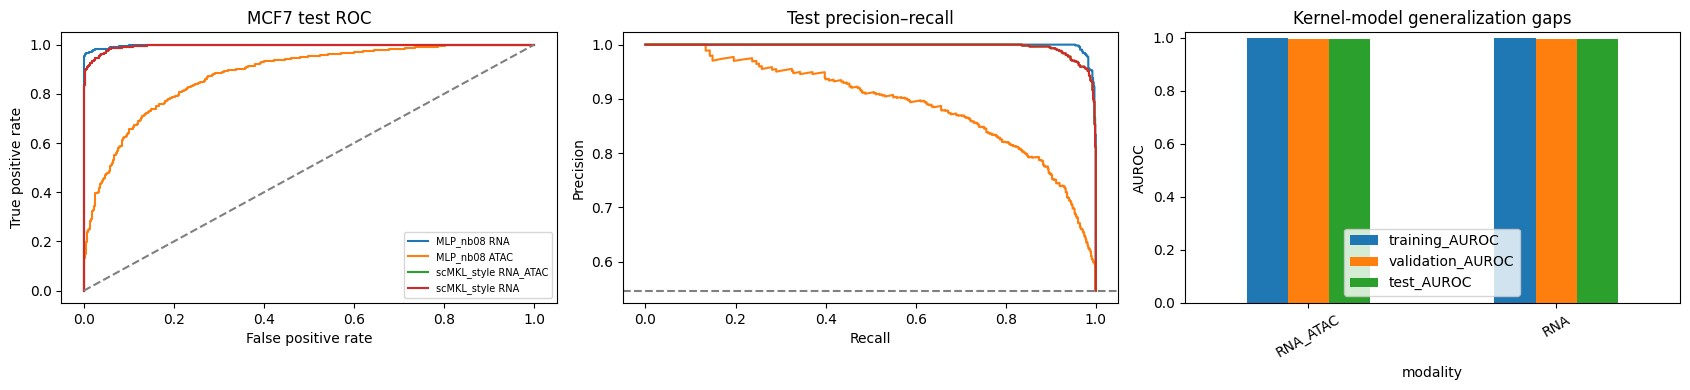

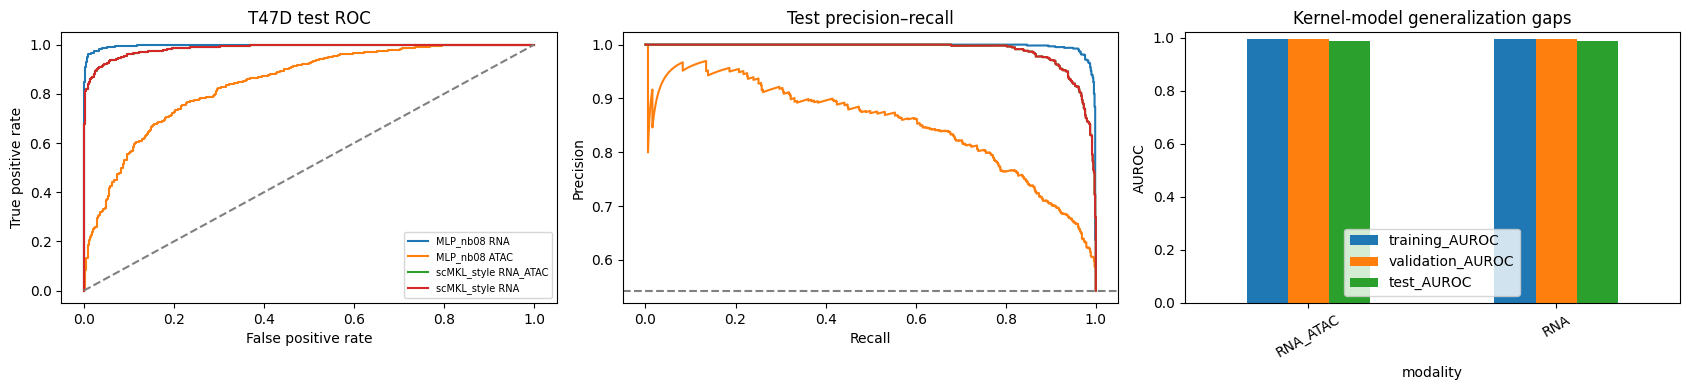

In [6]:
performance_plots(METRICS,GAPS,PREDICTIONS,OUTPUT)

## Selected pathways and motifs
Review all model weights, inspect integrated-model selection, and retain aliases for identical kernel
memberships. Plots show representative groups only, avoiding duplicate motif labels.
Coefficient magnitudes are not percentages of biological contribution or direct evidence of regulation.


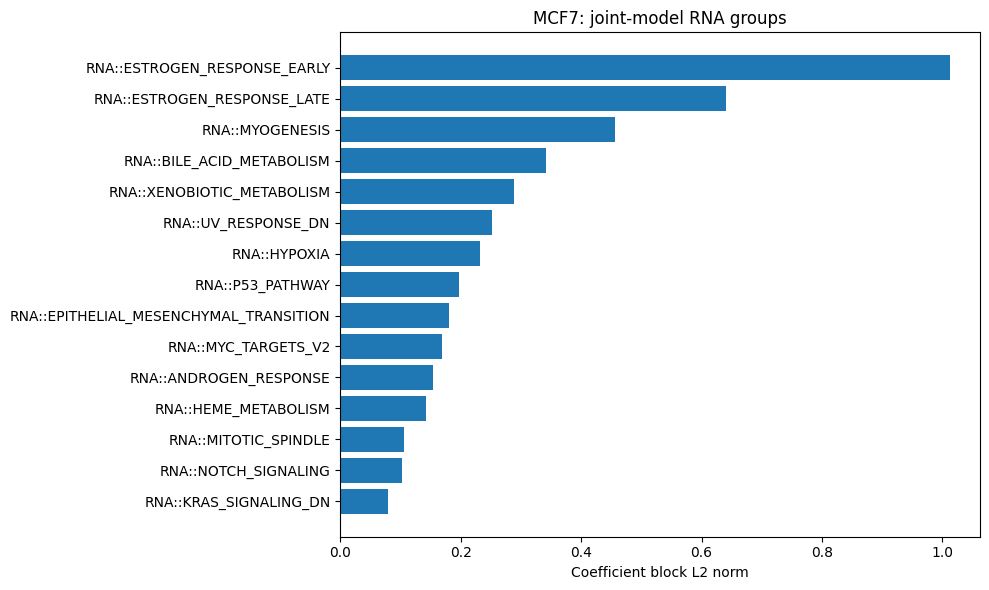

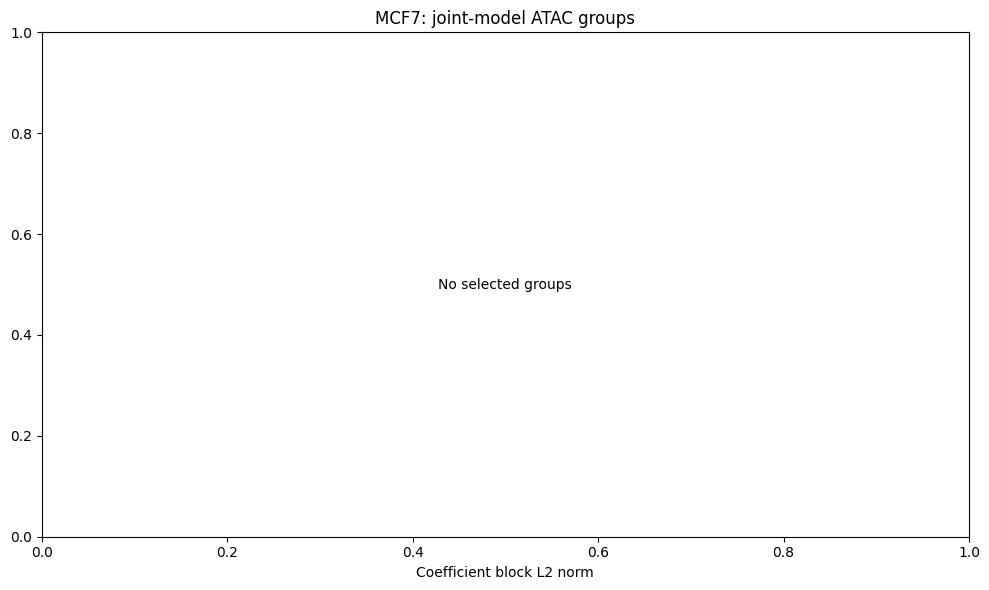

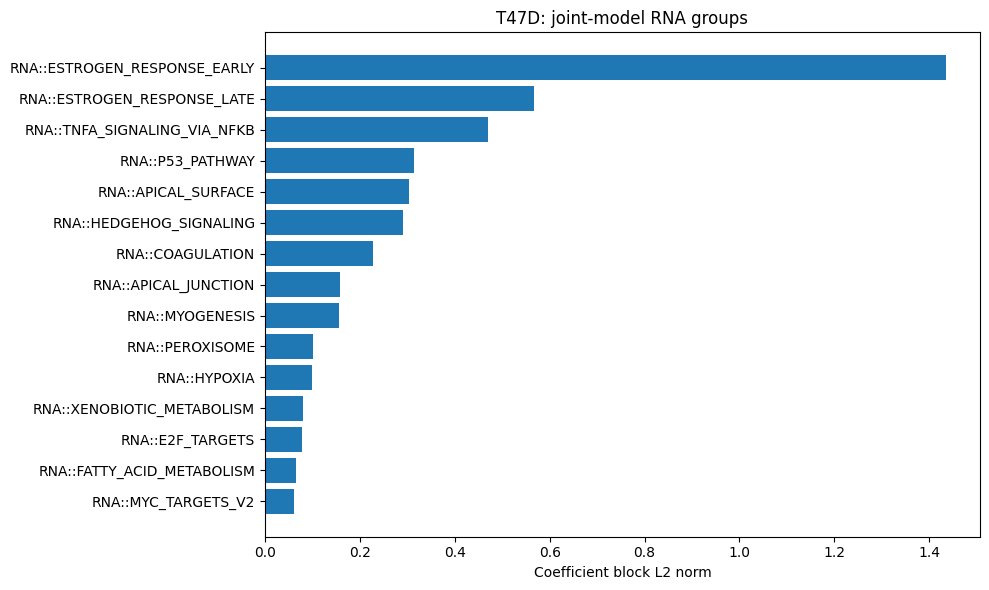

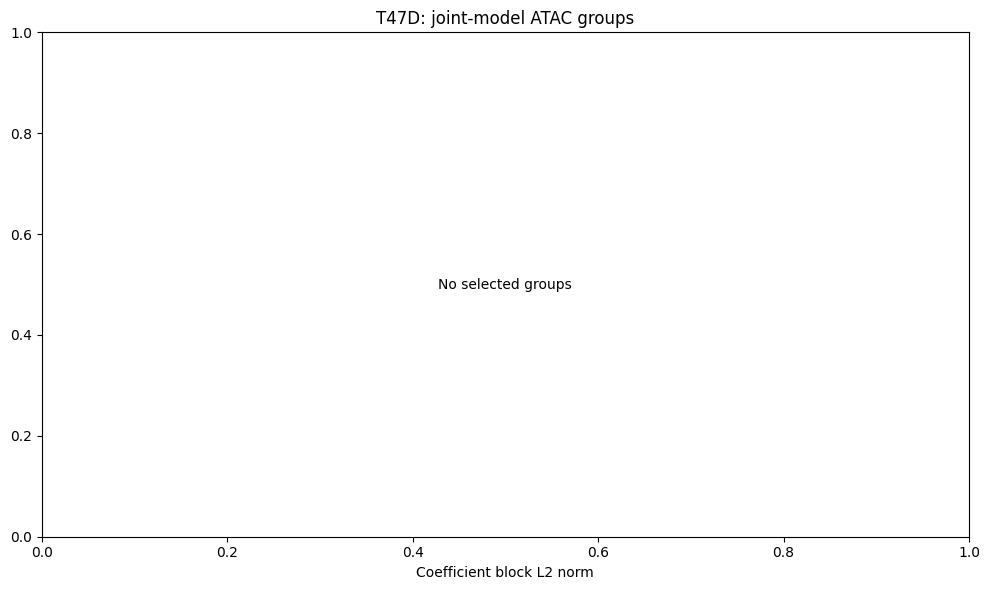

,group,modality,feature_count,sigma,rff_scale,map_file,coefficient_group_norm,selected,cell_line,input_mode
12,RNA::HALLMARK_ESTROGEN_RESPONSE_EARLY,RNA,89,13.184678,0.617932,group_0012.npz,1.011913,True,MCF7,RNA_ATAC
13,RNA::HALLMARK_ESTROGEN_RESPONSE_LATE,RNA,81,12.522110,0.618899,group_0013.npz,0.641220,True,MCF7,RNA_ATAC
15,RNA::HALLMARK_MYOGENESIS,RNA,41,8.833231,0.630862,group_0015.npz,0.456089,True,MCF7,RNA_ATAC
43,RNA::HALLMARK_BILE_ACID_METABOLISM,RNA,29,7.490557,0.627804,group_0043.npz,0.341412,True,MCF7,RNA_ATAC
31,RNA::HALLMARK_XENOBIOTIC_METABOLISM,RNA,51,9.921389,0.625808,group_0031.npz,0.288480,True,MCF7,RNA_ATAC
38,RNA::HALLMARK_UV_RESPONSE_DN,RNA,73,11.780362,0.637038,group_0038.npz,0.251636,True,MCF7,RNA_ATAC
1,RNA::HALLMARK_HYPOXIA,RNA,50,9.838343,0.625043,group_0001.npz,0.231181,True,MCF7,RNA_ATAC
36,RNA::HALLMARK_P53_PATHWAY,RNA,72,11.702459,0.635999,group_0036.npz,0.196483,True,MCF7,RNA_ATAC
29,RNA::HALLMARK_EPITHELIAL_MESENCHYMAL_TRANSITION,RNA,30,7.409650,0.642994,group_0029.npz,0.180958,True,MCF7,RNA_ATAC
28,RNA::HALLMARK_MYC_TARGETS_V2,RNA,16,5.395315,0.646448,group_0028.npz,0.169193,True,MCF7,RNA_ATAC


,group,norm_MCF7,selected_MCF7,norm_T47D,selected_T47D,represented_MCF7,represented_T47D
0,ATAC::MA0002.3__Runx1,0.0,False,0.0,False,True,True
1,ATAC::MA0003.5__TFAP2A,0.0,False,0.0,False,True,True
2,ATAC::MA0004.1__Arnt,0.0,False,0.0,False,True,True
3,ATAC::MA0006.2__Ahr::Arnt,0.0,False,0.0,False,True,True
4,ATAC::MA0007.4__Ar,0.0,False,0.0,False,True,True
5,ATAC::MA0009.2__TBXT,0.0,False,0.0,False,True,True
6,ATAC::MA0014.4__PAX5,0.0,False,0.0,False,True,True
7,ATAC::MA0017.3__NR2F1,0.0,False,0.0,False,True,True
8,ATAC::MA0018.5__CREB1,0.0,False,0.0,False,True,True
9,ATAC::MA0019.2__Ddit3::Cebpa,0.0,False,0.0,False,True,True


In [7]:
WEIGHTS, ALIASES, CROSS_LINE = review_groups(SOURCE,OUTPUT,INPUTS)
display(WEIGHTS[(WEIGHTS.input_mode=="RNA_ATAC") & WEIGHTS.selected]
        .sort_values(["cell_line","modality","coefficient_group_norm"],ascending=[True,True,False]))
display(CROSS_LINE.head(20))


## Relate predictive groups to earlier biology
Optional context is joined by exact Hallmark names and JASPAR motif IDs.
All scenarios are preserved in exported tables. A selected group with no matching context is not
evidence of biological absence; inspect coverage and resource versions. Earlier analyses do not
feed back into model fitting or selection.


In [8]:
CONTEXT_STATUS = biological_context(BASE,OUTPUT,INPUTS,ALIASES)
display(CONTEXT_STATUS)
print("Context tables saved under:",OUTPUT)


,file,status
0,/content/drive/MyDrive/breast-cancer-multiome-...,missing_optional_not_interpreted
1,/content/drive/MyDrive/breast-cancer-multiome-...,missing_optional_not_interpreted
2,/content/drive/MyDrive/breast-cancer-multiome-...,missing_optional_not_interpreted
3,/content/drive/MyDrive/breast-cancer-multiome-...,missing_optional_not_interpreted
4,/content/drive/MyDrive/breast-cancer-multiome-...,missing_optional_not_interpreted


Context tables saved under: /content/drive/MyDrive/breast-cancer-multiome-estrogen/results/tables/nb10/20261013T083832_186166Z


## Cross-cell-line treatment prediction — frozen models
**Question:** can an MCF7-trained model predict E2 versus Vehicle in T47D, and vice versa?
This predicts treatment across cell lines, not cell-line identity.

Default: **16 source→target cases**. nb08 RNA/ATAC; nb09 RNA/RNA+ATAC; nb11 v1 RNA+ATAC;
nb11 v2 RNA/ATAC/RNA+ATAC, each in both directions. Collapsed v2 ATAC models remain negative
controls. Explicit run IDs are below; remove a historical run only if deliberately excluding it.

Use the opposite line's existing nb08 **test cells only**, identical across model families.
Keep source feature order, centering/scaling, kernel frequencies/normalization, pathway masks,
peak-gene assignments and depth reference. No target statistics fit a transform, and no target
results select checkpoints or thresholds. Target-native scores use the separately trained model
from the same family/run on exactly those target test cells.

Each checkpoint must first reproduce its saved source-line test predictions within absolute/relative
tolerance 1e-4; otherwise transfer is withheld. Missing target RNA features use the source transformed
mean, with a predeclared 5% coverage limit and a full missing-feature list. Required ATAC peaks must
exist, and nb11 requires identical assay peak universes. No motif scan or target-specific mapping.

tqdm tracks evaluations and active kernels. Missing artifacts and verification failures are reported
separately, never assigned AUROC 0. The first pass hashes raw inputs and checkpoints and may take time.
Shared libraries, prior test inspection and absent biological replicates limit generalization claims.


In [9]:
RUN_CROSS_LINE_TRANSFER = True
NB08_TRANSFER_RUN_ID = HANDOFF["run_id"]
NB11_TRANSFER_RUNS = [
    {"run_id": "20261012T173612_419824Z", "version": 1},
    {"run_id": "20261012T180159_920277Z", "version": 2},
]
MAX_MISSING_RNA_FRACTION = 0.05  # Fixed before inspecting transfer results.
if RUN_CROSS_LINE_TRANSFER:
    import importlib.util, subprocess, sys
    packages = {"torch":"torch>=2.6,<3", "anndata":"anndata>=0.10,<0.13",
                "h5py":"h5py>=3.10,<4", "scipy":"scipy>=1.11,<2", "tqdm":"tqdm>=4.66,<5"}
    missing = [spec for module,spec in packages.items() if importlib.util.find_spec(module) is None]
    if missing: subprocess.check_call([sys.executable,"-m","pip","install","-q",*missing])


### Embedded frozen-inference implementation
Architecture definitions match the completed notebook versions. No model fitting is implemented.

In [10]:
if RUN_CROSS_LINE_TRANSFER:
    """Frozen cross-cell-line treatment prediction. No training or target-data fitting."""
    from pathlib import Path
    import gc
    import hashlib
    import json
    import math
    import platform
    import importlib.metadata
    import numpy as np
    import pandas as pd
    import scipy.sparse as sp
    import anndata as ad
    import h5py
    import torch
    from torch import nn
    from tqdm.auto import tqdm
    import matplotlib.pyplot as plt
    from sklearn.metrics import roc_auc_score,average_precision_score,accuracy_score,balanced_accuracy_score,f1_score,confusion_matrix

    def make_nb08_model(n_features,config):
        layers=[]
        for width in config["hidden_sizes"]:
            layers.extend([nn.Linear(n_features,width),nn.ReLU(),nn.Dropout(config["dropout"])])
            n_features=width
        return nn.Sequential(*layers,nn.Linear(n_features,1))

    class MaskedPathwayLayerV1(nn.Module):
        def __init__(self,mask,width):
            super().__init__()
            p,g=mask.shape
            expanded=torch.as_tensor(mask,dtype=torch.float32).repeat_interleave(width,dim=0)
            self.register_buffer("mask",expanded)
            self.weight=nn.Parameter(torch.empty(p*width,g))
            with torch.no_grad():
                self.weight.normal_()
                self.weight.mul_(torch.sqrt(2/expanded.sum(1,keepdim=True).clamp_min(1)))
                self.weight.mul_(expanded)
            self.p=p;self.width=width
            self.norm=nn.LayerNorm(width,elementwise_affine=False)
        def forward(self,x):
            h=nn.functional.linear(x,self.weight*self.mask).reshape(-1,self.p,self.width)
            return self.norm(nn.functional.gelu(h))

    class StochasticPathwayGateV1(nn.Module):
        def __init__(self,pathways,sigma):
            super().__init__()
            self.mu=nn.Parameter(torch.zeros(pathways));self.sigma=sigma
        def values(self):
            noise=torch.randn_like(self.mu)*self.sigma if self.training else 0
            return (self.mu+.5+noise).clamp(0,1)
        def expected_open(self):
            return .5*(1+torch.erf((self.mu+.5)/(self.sigma*math.sqrt(2))))

    class PathwayMLPV1(nn.Module):
        def __init__(self,structure,config):
            super().__init__()
            p=len(structure["pathways"]);d=config["pathway_width"]
            self.rna=MaskedPathwayLayerV1(structure["rna_mask"],d)
            self.atac=MaskedPathwayLayerV1(structure["atac_mask"],d)
            self.fusion_weight=nn.Parameter(torch.empty(p,2*d,d))
            nn.init.normal_(self.fusion_weight,std=math.sqrt(1/d))
            self.fusion_norm=nn.LayerNorm(d,elementwise_affine=False)
            self.gates=StochasticPathwayGateV1(p,config["gate_sigma"])
            self.head=nn.Sequential(nn.Linear(p*d,config["head_width"]),nn.ReLU(),
                nn.Dropout(config["dropout"]),nn.Linear(config["head_width"],1))
        def fused(self,r,a,ablate=None):
            hr,ha=self.rna(r),self.atac(a)
            if ablate is not None:
                branch,index=ablate
                keep=torch.ones(hr.shape[1],device=hr.device)
                if index is None:keep.zero_()
                else:keep[index]=0
                if branch=="RNA":hr=hr*keep[None,:,None]
                elif branch=="ATAC":ha=ha*keep[None,:,None]
            joined=torch.cat([hr,ha],dim=-1)
            return self.fusion_norm(nn.functional.gelu(torch.einsum("bpi,pid->bpd",joined,self.fusion_weight)))
        def classify(self,fused,ablate=None):
            z=fused*self.gates.values()[None,:,None]
            if ablate is not None and ablate[0]=="PATHWAY":
                keep=torch.ones(z.shape[1],device=z.device);keep[ablate[1]]=0
                z=z*keep[None,:,None]
            return self.head(z.flatten(1)).ravel()
        def forward(self,r,a,ablate=None):
            return self.classify(self.fused(r,a,ablate),ablate)

    class MaskedPathwayLayerV2(nn.Module):
        def __init__(self,mask,width):
            super().__init__()
            p,g=mask.shape
            expanded=torch.as_tensor(mask,dtype=torch.float32).repeat_interleave(width,dim=0)
            self.register_buffer("mask",expanded)
            self.weight=nn.Parameter(torch.empty(p*width,g))
            with torch.no_grad():
                self.weight.normal_()
                self.weight.mul_(torch.sqrt(2/expanded.sum(1,keepdim=True).clamp_min(1)))
                self.weight.mul_(expanded)
            self.p=p;self.width=width
            self.norm=nn.Tanh()
        def forward(self,x):
            h=nn.functional.linear(x,self.weight*self.mask).reshape(-1,self.p,self.width)
            return self.norm(h)

    class StochasticPathwayGateV2(nn.Module):
        def __init__(self,pathways,sigma,initial_mu):
            super().__init__()
            self.mu=nn.Parameter(torch.full((pathways,),float(initial_mu)));self.sigma=sigma
        def values(self):
            noise=torch.randn_like(self.mu)*self.sigma if self.training else 0
            return (self.mu+.5+noise).clamp(0,1)
        def expected_open(self):
            return .5*(1+torch.erf((self.mu+.5)/(self.sigma*math.sqrt(2))))

    class PathwayMLPV2(nn.Module):
        def __init__(self,structure,config,mode):
            super().__init__()
            if mode not in ("RNA","ATAC","RNA_ATAC"):raise ValueError("Unknown input mode.")
            self.mode=mode
            p=len(structure["pathways"]);d=config["pathway_width"]
            self.pathways=p;self.width=d
            self.rna=MaskedPathwayLayerV2(structure["rna_mask"],d) if mode!="ATAC" else None
            self.atac=MaskedPathwayLayerV2(structure["atac_mask"],d) if mode!="RNA" else None
            self.fusion_weight=nn.Parameter(torch.empty(p,2*d,d))
            nn.init.normal_(self.fusion_weight,std=math.sqrt(1/d))
            self.fusion_norm=nn.Tanh()
            self.gates=StochasticPathwayGateV2(p,config["gate_sigma"],config["gate_initial_mu"])
            self.head=nn.Sequential(nn.Linear(p*d,config["head_width"]),nn.ReLU(),
                nn.Dropout(config["dropout"]),nn.Linear(config["head_width"],1))
        def fused(self,r,a,ablate=None):
            zero=r.new_zeros((len(r),self.pathways,self.width))
            hr=self.rna(r) if self.rna is not None else zero
            ha=self.atac(a) if self.atac is not None else zero
            if ablate is not None:
                branch,index=ablate
                keep=torch.ones(hr.shape[1],device=hr.device)
                if index is None:keep.zero_()
                else:keep[index]=0
                if branch=="RNA":hr=hr*keep[None,:,None]
                elif branch=="ATAC":ha=ha*keep[None,:,None]
            joined=torch.cat([hr,ha],dim=-1)
            return self.fusion_norm(torch.einsum("bpi,pid->bpd",joined,self.fusion_weight))
        def classify(self,fused,ablate=None):
            z=fused*self.gates.values()[None,:,None]
            if ablate is not None and ablate[0]=="PATHWAY":
                keep=torch.ones(z.shape[1],device=z.device);keep[ablate[1]]=0
                z=z*keep[None,:,None]
            return self.head(z.flatten(1)).ravel()
        def forward(self,r,a,ablate=None):
            return self.classify(self.fused(r,a,ablate),ablate)

    def transfer_json(path,value):
        Path(path).write_text(json.dumps(value,indent=2,allow_nan=False)+"\n")

    def align_transfer_features(x,available,required):
        """Exact ID alignment; absent features remain zero until source-mean imputation."""
        available=pd.Index(available);required=pd.Index(required)
        if not available.is_unique or not required.is_unique:raise ValueError("Duplicate feature IDs.")
        locations=available.get_indexer(required);valid=np.flatnonzero(locations>=0)
        coo=x[:,locations[valid]].tocoo()
        aligned=sp.csr_matrix((coo.data,(coo.row,valid[coo.col])),shape=(x.shape[0],len(required)),dtype=np.float32)
        return aligned,locations<0

    def transfer_metrics(y,score,threshold):
        if not np.isfinite(score).all():raise ValueError("Nonfinite prediction scores.")
        if set(np.asarray(y).tolist())!={0,1}:raise ValueError("Both treatment classes required.")
        pred=score>=threshold
        tn,fp,fn,tp=confusion_matrix(y,pred,labels=[0,1]).ravel()
        return dict(AUROC=float(roc_auc_score(y,score)),average_precision=float(average_precision_score(y,score)),
            accuracy=float(accuracy_score(y,pred)),balanced_accuracy=float(balanced_accuracy_score(y,pred)),
            F1_E2=float(f1_score(y,pred,zero_division=0)),n_cells=len(y),
            TN=int(tn),FP=int(fp),FN=int(fn),TP=int(tp))

    class TransferContext:
        def __init__(self,base,output,nb08_run_id,max_missing_fraction=.05,batch_size=128):
            self.base=Path(base);self.out=Path(output)/"cross_cell_line";self.out.mkdir(exist_ok=True)
            self.baseline=self.base/"results/tables/nb08"/nb08_run_id
            self.max_missing=max_missing_fraction;self.batch_size=batch_size
            self.device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
            self.hashes={};self.coverage=[];self.raw_cache={};self.manifests={}
            self.handoff=self.read_json(self.baseline/"integration_handoff.json")
            if self.handoff["positive_class"]!="E2" or self.handoff["run_id"]!=nb08_run_id:
                raise ValueError("Unexpected baseline treatment mapping.")
            self.provenance=self.read_csv(self.baseline/"input_provenance.csv")
            for line in ("MCF7","T47D"):
                path=self.baseline/self.handoff["manifests"][line]["file"]
                if self.record(path)!=self.handoff["manifests"][line]["sha256"]:raise ValueError("Baseline split hash mismatch.")
                m=self.read_csv(path,dtype={"cell_id":str})
                if not m.cell_id.is_unique or set(m.cell_line)!={line} or not np.array_equal(m.label_E2,(m.treatment=="E2").astype(int)):
                    raise ValueError("Invalid source/target labels.")
                self.manifests[line]=m
            transfer_json(self.out/"environment.json",{"python":platform.python_version(),"device":str(self.device),
                "packages":{name:importlib.metadata.version(name) for name in ("torch","numpy","pandas","scipy","anndata","h5py","scikit-learn")}})
        def record(self,path):
            path=Path(path)
            if not path.is_file():raise FileNotFoundError(f"Required saved artifact is missing: {path}")
            key=str(path)
            if key not in self.hashes:
                h=hashlib.sha256()
                with path.open("rb") as f:
                    for block in iter(lambda:f.read(8*1024*1024),b""):h.update(block)
                self.hashes[key]=h.hexdigest()
            return self.hashes[key]
        def read_json(self,path):
            self.record(path);return json.loads(Path(path).read_text())
        def read_csv(self,path,**kwargs):
            self.record(path);return pd.read_csv(path,**kwargs)
        def read_npz(self,path):
            self.record(path)
            with np.load(path,allow_pickle=False) as f:return {key:f[key] for key in f.files}
        def test_frame(self,line):
            return self.manifests[line].loc[lambda f:f["split"].eq("test")].reset_index(drop=True)
        def raw(self,line,modality):
            key=(line,modality)
            if key in self.raw_cache:return self.raw_cache[key]
            suffix="RNA_paper_qc" if modality=="RNA" else "ATAC_paired_paper_qc"
            path=self.base/"data/processed"/f"{line}_{suffix}.h5ad"
            expected=self.provenance[(self.provenance.cell_line==line)&(self.provenance.modality==modality)]
            if len(expected)!=1 or self.record(path)!=expected.iloc[0].sha256:
                raise ValueError(f"{line} {modality}: raw input differs from training.")
            with h5py.File(path,"r") as f:
                obs=ad.io.read_elem(f["obs"]);var=ad.io.read_elem(f["var"])
                m=self.manifests[line]
                if list(obs.index.astype(str))!=m.cell_id.tolist() or not np.array_equal(obs.treatment.astype(str),m.treatment):
                    raise ValueError("Input cell order/treatment differs from split manifest.")
                x=ad.io.read_elem(f["layers/counts" if modality=="RNA" else "X"])
            if not sp.issparse(x):raise TypeError("Expected sparse counts.")
            ix=np.flatnonzero(m["split"].eq("test"))
            x=x[ix].tocsr().astype(np.float32);x.sum_duplicates();x.eliminate_zeros()
            if not np.isfinite(x.data).all() or (x.data<0).any() or not np.allclose(x.data,np.rint(x.data)):
                raise ValueError("Invalid raw counts.")
            if modality=="RNA":x.data=np.log1p(x.data)
            else:x.data.fill(1)
            result=(x,var.index.astype(str).to_numpy())
            self.raw_cache[key]=result
            return result
        def aligned(self,line,modality,required,tag):
            raw,ids=self.raw(line,modality)
            x,missing=align_transfer_features(raw,ids,required)
            count=int(missing.sum());fraction=count/max(1,len(required))
            self.coverage.append(dict(model=tag,evaluation_line=line,modality=modality,required=len(required),
                missing=count,missing_fraction=fraction,policy="source mean in transformed RNA space" if modality=="RNA" else "strict peak identity"))
            safe=tag.replace("/","_")
            pd.DataFrame({"feature_id":np.asarray(required)[missing]}).to_csv(self.out/f"{safe}_{line}_{modality}_missing_features.csv",index=False)
            if count and (modality=="ATAC" or fraction>self.max_missing):
                raise ValueError(f"{tag}: {count}/{len(required)} {modality} features absent in {line}; coverage policy failed.")
            return x,missing
        def saved_scores(self,path,line,column):
            frame=self.read_csv(path,dtype={"cell_id":str});expected=self.test_frame(line)
            if not frame.cell_id.is_unique or set(frame.cell_id)!=set(expected.cell_id):raise ValueError("Saved prediction cells differ.")
            frame=frame.set_index("cell_id").loc[expected.cell_id]
            if not np.array_equal(frame.label_E2,expected.label_E2):raise ValueError("Saved prediction labels differ.")
            return frame[column].to_numpy(dtype=float)
        def verify_model_splits(self,folder):
            for line in ("MCF7","T47D"):
                if self.record(Path(folder)/f"{line}_splits.csv")!=self.handoff["manifests"][line]["sha256"]:
                    # Some nb11 files were reserialized; verify complete manifest values in that case.
                    frame=self.read_csv(Path(folder)/f"{line}_splits.csv",dtype={"cell_id":str})
                    columns=["cell_id","cell_line","treatment","label_E2","split"]
                    if not frame[columns].equals(self.manifests[line][columns]):raise ValueError("Model split mismatch.")
        def save_audit(self):
            pd.DataFrame([{"path":p,"sha256":h} for p,h in self.hashes.items()]).to_csv(self.out/"input_artifact_hashes.csv",index=False)
            pd.DataFrame(self.coverage).to_csv(self.out/"feature_coverage.csv",index=False)

    @torch.inference_mode()
    def transfer_torch_scores(model,matrices,center_scale,context,mode="single"):
        model.eval();scores=[]
        n=matrices[0][0].shape[0]
        for start in range(0,n,context.batch_size):
            tensors=[]
            for (x,missing),(center,scale) in zip(matrices,center_scale):
                dense=x[start:start+context.batch_size].toarray()
                if np.any(missing):dense[:,missing]=center[missing]
                dense=(dense-center)/scale
                if not np.isfinite(dense).all():raise ValueError("Nonfinite source-scaled inputs.")
                tensors.append(torch.as_tensor(dense,dtype=torch.float32,device=context.device))
            logits=model(tensors[0]).ravel() if mode=="single" else model(*tensors).ravel()
            scores.append(logits.sigmoid().cpu().numpy())
        return np.concatenate(scores)

    def load_nb08_transfer(context,source,mode):
        tag=f"{source}_{mode}";folder=context.base/context.handoff["models_directory"]
        spec=context.read_json(folder/f"{tag}_model_spec.json")
        if spec["positive_class"]!="E2" or spec["cell_line"]!=source or spec["modality"]!=mode:
            raise ValueError("nb08 model identity mismatch.")
        if spec["split_sha256"]!=context.handoff["manifests"][source]["sha256"]:raise ValueError("Model split checksum mismatch.")
        prep=context.read_npz(folder/spec["preprocessing"])
        model=make_nb08_model(len(prep["feature_ids"]),spec["config"]).to(context.device)
        context.record(folder/spec["weights"])
        model.load_state_dict(torch.load(folder/spec["weights"],map_location=context.device,weights_only=True),strict=True)
        def scorer(line):
            x,missing=context.aligned(line,mode,prep["feature_ids"],"nb08_"+tag)
            return transfer_torch_scores(model,[(x,missing)],[(prep["center"],prep["scale"])],context)
        def saved(line):return context.baseline/f"{line}_{mode}_test_predictions.csv"
        return scorer,saved,"probability_E2",.5

    def transfer_map_folder(context,run,line,modality):
        folder=Path(run);seen=set()
        while True:
            if folder.name in seen:raise ValueError("Cyclic nb09 cache chain.")
            seen.add(folder.name)
            context.verify_model_splits(folder)
            pointer=folder/f"{line}_{modality}_cache.json"
            if not pointer.exists():break
            origin=context.read_json(pointer)["source_run"]
            if not isinstance(origin,str) or "/" in origin or "\\" in origin or origin in ("",".",".."):
                raise ValueError("Invalid cache origin.")
            if origin==folder.name:break
            folder=context.base/"results/tables/nb09"/origin
        return context.base/"data/processed/nb09"/folder.name/f"{line}_{modality}_maps"

    def load_nb09_transfer(context,source,mode,run_id):
        run=context.base/"results/tables/nb09"/run_id;context.verify_model_splits(run)
        artifact=context.base/"data/processed/nb09"/run_id;tag=f"{source}_{mode}"
        spec=context.read_json(artifact/f"{tag}_model_spec.json")
        if not spec["selection"]["converged"]:raise ValueError("Cannot evaluate unconverged model.")
        if spec["target_encoding"]!={"E2":1,"Vehicle":-1} or spec["classification_threshold"]!=0:
            raise ValueError("Unexpected kernel score encoding or threshold.")
        model=context.read_npz(artifact/f"{tag}_model.npz")
        modalities=["RNA"] if mode=="RNA" else ["RNA","ATAC"]
        if model["modalities"].tolist()!=modalities or spec["modalities"]!=modalities:raise ValueError("Kernel modality mismatch.")
        resources=[];offset=0;group_order=[]
        for modality in modalities:
            features=context.read_csv(run/f"{source}_{modality}_features.csv")
            kernels=context.read_csv(run/f"{source}_{modality}_kernels.csv")
            maps=transfer_map_folder(context,run,source,modality)
            group_order.extend(kernels["group"].tolist())
            for _,row in kernels.iterrows():
                g=context.read_npz(maps/row["map_file"])
                width=2*g["frequencies"].shape[1]
                weight=model["coef"][offset:offset+width];offset+=width
                if len(weight)!=width:raise ValueError("Kernel coefficient length mismatch.")
                if np.any(weight!=0):resources.append((modality,features.feature_id.astype(str).to_numpy(),g,weight))
        if offset!=len(model["coef"]) or group_order!=spec["group_order"]:raise ValueError("Kernel group order mismatch.")
        def scorer(line):
            score=np.full(len(context.test_frame(line)),float(model["intercept"]),dtype=np.float64)
            aligned={}
            for modality,ids,g,weight in tqdm(resources,desc=f"{source} -> {line}: {mode} kernels",leave=False):
                if modality not in aligned:aligned[modality]=context.aligned(line,modality,ids,"nb09_"+tag)
                x,missing=aligned[modality];cols=g["feature_columns"].astype(int)
                center=g["input_center"];scale=g["input_scale"];missing_group=missing[cols]
                d=g["frequencies"].shape[1]
                for begin in range(0,len(score),context.batch_size):
                    dense=x[begin:begin+context.batch_size,cols].toarray()
                    if np.any(missing_group):dense[:,missing_group]=center[missing_group]
                    angle=((dense-center)/scale)@g["frequencies"]
                    block=np.concatenate((np.cos(angle)/np.sqrt(d),np.sin(angle)/np.sqrt(d)),axis=1).astype(np.float32)
                    block=(block-g["rff_center"])/float(g["rff_scale"])
                    score[begin:begin+len(dense)]+=block@weight
            return score
        def saved(line):return run/f"{line}_{mode}_test_predictions.csv"
        return scorer,saved,"decision_score_E2",0.

    def load_nb11_transfer(context,source,mode,run_id,version):
        run=context.base/"results/tables/nb11"/run_id;context.verify_model_splits(run)
        cfg=context.read_json(run/"config.json")
        if int(cfg.get("model_version",1))!=version:raise ValueError("nb11 architecture version mismatch.")
        if version==1 and mode!="RNA_ATAC":raise ValueError("nb11 v1 has only multimodal models.")
        folder=context.base/"data/processed/nb11"/run_id/source
        meta=context.read_json(folder/"prepared.json")
        if context.record(folder/"structure.npz")!=meta["checksums"]["structure.npz"]:
            raise ValueError("Source pathway structure checksum differs.")
        st=context.read_npz(folder/"structure.npz")
        model=(PathwayMLPV2(st,cfg,mode) if version==2 else PathwayMLPV1(st,cfg)).to(context.device)
        weights=folder/"models"/mode/"best.pt" if version==2 else folder/"best.pt"
        context.record(weights)
        model.load_state_dict(torch.load(weights,map_location=context.device,weights_only=True),strict=True)
        tag=f"nb11_v{version}_{source}_{mode}"
        links=None
        if mode!="RNA":
            links=context.read_csv(run/f"{source}_peak_gene_links.csv")
            links=links[links.gene.isin(st["atac_genes"])].copy()
            if links.duplicated(["peak","gene"]).any():raise ValueError("Duplicate source peak/gene links.")
        def scorer(line):
            count=len(context.test_frame(line))
            if mode!="ATAC":
                rx,rm=context.aligned(line,"RNA",st["rna_genes"],tag)
            else:
                rx=sp.csr_matrix((count,len(st["rna_genes"])),dtype=np.float32);rm=np.ones(rx.shape[1],bool)
            if mode!="RNA":
                b,peaks=context.raw(line,"ATAC")
                _,source_peaks=context.raw(source,"ATAC")
                if set(peaks)!=set(source_peaks):
                    raise ValueError("ATAC assay peak universes differ; source depth transform cannot be reproduced.")
                peak_index=pd.Index(peaks).get_indexer(links.peak)
                genes=pd.Index(st["atac_genes"]).get_indexer(links.gene)
                if (peak_index<0).any() or (genes<0).any():raise ValueError("Source ATAC links cannot be aligned.")
                assignment=sp.csr_matrix((links.assignment_weight.to_numpy(dtype=np.float32),(peak_index,genes)),
                    shape=(len(peaks),len(st["atac_genes"])),dtype=np.float32)
                coverage=np.asarray(assignment.sum(axis=0)).ravel()
                if (coverage<=0).any():raise ValueError("Source accessibility features lost all peak coverage.")
                depth=np.asarray(b.getnnz(axis=1)).ravel().astype(np.float32)
                if (depth<=0).any():raise ValueError("Zero-depth target ATAC cell.")
                reference=float(st["atac_training_median_depth"])
                ax=(b@assignment).multiply(1/np.maximum(coverage,1e-12)).multiply((reference/depth)[:,None]).tocsr()
                ax.eliminate_zeros();ax.data=np.log1p(ax.data);am=np.zeros(ax.shape[1],bool)
                context.coverage.append(dict(model=tag,evaluation_line=line,modality="ATAC_gene_accessibility",
                    required=ax.shape[1],missing=0,missing_fraction=0.,policy="source peak links, weights, coverage and depth reference"))
            else:
                ax=sp.csr_matrix((count,len(st["atac_genes"])),dtype=np.float32);am=np.ones(ax.shape[1],bool)
            return transfer_torch_scores(model,[(rx,rm),(ax,am)],
                [(st["rna_mean"],st["rna_sd"]),(st["atac_mean"],st["atac_sd"])],context,mode="paired")
        def saved(line):
            return run/f"{line}_{mode}"/f"{line}_test_predictions.csv" if version==2 else run/f"{line}_test_predictions.csv"
        return scorer,saved,"probability_E2",.5

    def run_cross_line_transfer(base,output,nb08_run_id,nb09_run_id,nb11_runs,max_missing_fraction=.05):
        """Source test reproduction is required before every opposite-line evaluation."""
        context=TransferContext(base,output,nb08_run_id,max_missing_fraction)
        jobs=[]
        for source,target in (("MCF7","T47D"),("T47D","MCF7")):
            jobs.extend(dict(family="nb08_MLP",mode=mode,run_id=nb08_run_id,version=0,source=source,target=target) for mode in ("RNA","ATAC"))
            jobs.extend(dict(family="nb09_kernel",mode=mode,run_id=nb09_run_id,version=0,source=source,target=target) for mode in ("RNA","RNA_ATAC"))
            for run in nb11_runs:
                version=run["version"]
                if version not in (1,2):raise ValueError("Only nb11 versions 1 and 2 are supported.")
                jobs.extend(dict(family=f"nb11_v{version}",mode=mode,run_id=run["run_id"],version=version,source=source,target=target)
                            for mode in (("RNA_ATAC",) if version==1 else ("RNA","ATAC","RNA_ATAC")))
        transfer_json(context.out/"transfer_protocol.json",dict(nb08_run_id=nb08_run_id,nb09_run_id=nb09_run_id,
            nb11_runs=nb11_runs,target="E2 versus Vehicle within the opposite cell line",evaluation_subset="nb08 held-out test cells only",
            missing_RNA_policy="source transformed mean; no target statistics",maximum_missing_RNA_fraction=max_missing_fraction,
            missing_ATAC_policy="fail if required peak absent or nb11 assay peak universe differs",
            model_selection="frozen source checkpoints; no target tuning",score_reproduction_atol=1e-4,score_reproduction_rtol=1e-4))
        pd.DataFrame(jobs).to_csv(context.out/"requested_models.csv",index=False)
        records=[]
        for job in tqdm(jobs,desc="Frozen cross-cell-line evaluations"):
            scorer=None
            label=f"{job['family']}_{job['run_id']}_{job['mode']}_{job['source']}_to_{job['target']}"
            row=dict(job,model=job["family"]+" "+job["mode"],status="failed")
            try:
                if job["family"]=="nb08_MLP":scorer,saved,column,threshold=load_nb08_transfer(context,job["source"],job["mode"])
                elif job["family"]=="nb09_kernel":scorer,saved,column,threshold=load_nb09_transfer(context,job["source"],job["mode"],job["run_id"])
                else:scorer,saved,column,threshold=load_nb11_transfer(context,job["source"],job["mode"],job["run_id"],job["version"])
                own=scorer(job["source"])
                original=context.saved_scores(saved(job["source"]),job["source"],column)
                maximum_error=float(np.max(np.abs(own-original)))
                row["source_reproduction_max_absolute_error"]=maximum_error
                if not np.allclose(own,original,atol=1e-4,rtol=1e-4):
                    raise ValueError(f"Source test predictions were not reproduced (max error {maximum_error:.6g}); transfer withheld.")
                own_metrics=transfer_metrics(context.test_frame(job["source"]).label_E2,own,threshold)
                row["source_test_AUROC"]=own_metrics["AUROC"]
                # No target transformation is fitted; labels enter metrics only after frozen scoring.
                transferred=scorer(job["target"])
                frame=context.test_frame(job["target"]).copy()
                frame["source_cell_line"]=job["source"];frame["score"]=transferred
                frame["score_type"]=column;frame["decision_threshold"]=threshold
                frame["predicted_label_E2"]=(transferred>=threshold).astype(int)
                frame.to_csv(context.out/f"{label}_predictions.csv",index=False)
                row.update(transfer_metrics(frame.label_E2,transferred,threshold))
                target_native=context.saved_scores(saved(job["target"]),job["target"],column)
                native_metrics=transfer_metrics(frame.label_E2,target_native,threshold)
                row["target_native_AUROC"]=native_metrics["AUROC"]
                row["AUROC_transfer_minus_target_native"]=row["AUROC"]-native_metrics["AUROC"]
                row["constant_predictions"]=bool(np.ptp(transferred)<1e-8)
                row["status"]="complete"
                print(f"{label}: transfer AUROC={row['AUROC']:.4f}; target-native AUROC={row['target_native_AUROC']:.4f}")
            except Exception as error:
                row["error"]=f"{type(error).__name__}: {error}"
                print(f"{label}: NOT EVALUATED — {row['error']}")
            finally:
                records.append(row)
                pd.DataFrame(records).to_csv(context.out/"transfer_results.csv",index=False)
                context.save_audit()
                del scorer;gc.collect()
                if torch.cuda.is_available():torch.cuda.empty_cache()
        result=pd.DataFrame(records)
        done=result[result.status.eq("complete")]
        if len(done):
            fig,axes=plt.subplots(1,2,figsize=(14,5))
            for ax,(source,target) in zip(axes,(("MCF7","T47D"),("T47D","MCF7"))):
                sub=done[(done.source==source)&(done.target==target)].copy()
                if len(sub):
                    sub["label"]=sub["model"]+" ["+sub["run_id"].str[:8]+"]"
                    sub.set_index("label")[["AUROC","target_native_AUROC"]].plot.barh(ax=ax)
                    ax.axvline(.5,color="gray",linestyle="--")
                ax.set(title=f"{source} → {target}",xlabel="Test AUROC",xlim=(0,1.02))
            fig.tight_layout();fig.savefig(context.out/"cross_cell_line_AUROC.png",dpi=160);plt.show();plt.close(fig)
        report=["# Frozen cross-cell-line treatment prediction","",
            f"Completed {len(done)} of {len(jobs)} requested evaluations. Missing/invalid artifacts are listed in transfer_results.csv.",
            "","Source models predict E2 versus Vehicle in the opposite cell line; cell-line identity is not the prediction target.",
            "All evaluations use the opposite line's existing held-out test cells. No training, calibration, threshold selection or target-statistic fitting occurs.",
            "","Target-native scores are the same model family/run trained on the target line and evaluated on those same target test cells.",
            "This comparison measures within-dataset transfer, not independent patient/replicate generalization. Shared libraries and treatment/library confounding remain possible.",
            "Both nb11 versions are included when their saved checkpoints exist. Collapsed ATAC models are retained as negative controls.",
            "Missing RNA features use source means, with the declared coverage limit. Review feature_coverage.csv and missing-feature lists.",
            "A source-prediction reproduction failure prevents transfer for that model. Do not interpret a failed row as a low-performing model.",""]
        for _,row in done.iterrows():
            report.append(f"- {row['model']} ({row['run_id']}), {row['source']} → {row['target']}: AUROC {row['AUROC']:.4f}, target-native {row['target_native_AUROC']:.4f}.")
        (context.out/"transfer_report.md").write_text("\n".join(report)+"\n")
        print(f"Cross-line evaluation: {len(done)}/{len(jobs)} completed. Review failed rows before calling the comparison complete.")
        return result


Frozen cross-cell-line evaluations:   0%|          | 0/16 [00:00<?, ?it/s]

nb08_MLP_20261011T103750_408739Z_RNA_MCF7_to_T47D: transfer AUROC=0.9614; target-native AUROC=0.9969
nb08_MLP_20261011T103750_408739Z_ATAC_MCF7_to_T47D: transfer AUROC=0.7359; target-native AUROC=0.8438


MCF7 -> MCF7: RNA kernels:   0%|          | 0/27 [00:00<?, ?it/s]

MCF7 -> T47D: RNA kernels:   0%|          | 0/27 [00:00<?, ?it/s]

nb09_kernel_20261012T114858_335840Z_RNA_MCF7_to_T47D: transfer AUROC=0.9660; target-native AUROC=0.9863


...

T47D -> MCF7: RNA kernels:   0%|          | 0/22 [00:00<?, ?it/s]

nb09_kernel_20261012T114858_335840Z_RNA_T47D_to_MCF7: transfer AUROC=0.9745; target-native AUROC=0.9954


T47D -> T47D: RNA_ATAC kernels:   0%|          | 0/22 [00:00<?, ?it/s]

T47D -> MCF7: RNA_ATAC kernels:   0%|          | 0/22 [00:00<?, ?it/s]

nb09_kernel_20261012T114858_335840Z_RNA_ATAC_T47D_to_MCF7: transfer AUROC=0.9745; target-native AUROC=0.9954
nb11_v1_20261012T173612_419824Z_RNA_ATAC_T47D_to_MCF7: transfer AUROC=0.9151; target-native AUROC=0.9557
nb11_v2_20261012T180159_920277Z_RNA_T47D_to_MCF7: transfer AUROC=0.9756; target-native AUROC=0.9938
nb11_v2_20261012T180159_920277Z_ATAC_T47D_to_MCF7: transfer AUROC=0.5000; target-native AUROC=0.5000
nb11_v2_20261012T180159_920277Z_RNA_ATAC_T47D_to_MCF7: transfer AUROC=0.9751; target-native AUROC=0.9852


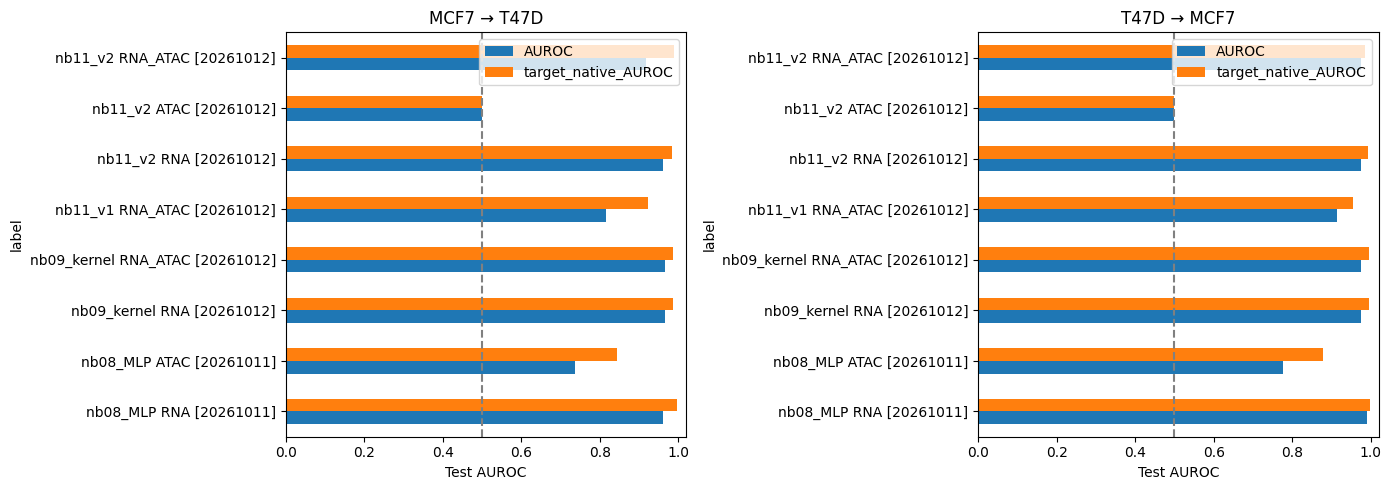

Cross-line evaluation: 16/16 completed. Review failed rows before calling the comparison complete.


,family,mode,run_id,version,source,target,model,status,source_reproduction_max_absolute_error,source_test_AUROC,...,balanced_accuracy,F1_E2,n_cells,TN,FP,FN,TP,target_native_AUROC,AUROC_transfer_minus_target_native,constant_predictions
0,nb08_MLP,RNA,20261011T103750_408739Z,0,MCF7,T47D,nb08_MLP RNA,complete,3.103462e-07,0.998052,...,0.830670,0.869401,1313,417,183,24,689,0.996933,-0.035577,False
1,nb08_MLP,ATAC,20261011T103750_408739Z,0,MCF7,T47D,nb08_MLP ATAC,complete,4.446129e-07,0.878609,...,0.658423,0.660674,1313,419,181,272,441,0.843777,-0.107842,False
2,nb09_kernel,RNA,20261012T114858_335840Z,0,MCF7,T47D,nb09_kernel RNA,complete,6.058253e-07,0.995371,...,0.865497,0.891786,1313,463,137,29,684,0.986274,-0.020283,False
3,nb09_kernel,RNA_ATAC,20261012T114858_335840Z,0,MCF7,T47D,nb09_kernel RNA_ATAC,complete,4.108297e-07,0.995366,...,0.865497,0.891786,1313,463,137,29,684,0.986276,-0.020299,False
4,nb11_v1,RNA_ATAC,20261012T173612_419824Z,1,MCF7,T47D,nb11_v1 RNA_ATAC,complete,1.801978e-06,0.955729,...,0.722911,0.770235,1313,371,229,123,590,0.922929,-0.107450,False
5,nb11_v2,RNA,20261012T180159_920277Z,2,MCF7,T47D,nb11_v2 RNA,complete,3.758842e-07,0.993837,...,0.892314,0.902098,1313,528,72,68,645,0.983576,-0.023791,False
6,nb11_v2,ATAC,20261012T180159_920277Z,2,MCF7,T47D,nb11_v2 ATAC,complete,1.074371e-08,0.500000,...,0.500000,0.703850,1313,0,600,0,713,0.500000,0.000000,True
7,nb11_v2,RNA_ATAC,20261012T180159_920277Z,2,MCF7,T47D,nb11_v2 RNA_ATAC,complete,6.357254e-07,0.985217,...,0.829031,0.852901,1313,463,137,81,632,0.988747,-0.070545,False
8,nb08_MLP,RNA,20261011T103750_408739Z,0,T47D,MCF7,nb08_MLP RNA,complete,3.001167e-07,0.996933,...,0.920505,0.936691,1204,465,81,7,651,0.998052,-0.006803,False
9,nb08_MLP,ATAC,20261011T103750_408739Z,0,T47D,MCF7,nb08_MLP ATAC,complete,3.738014e-07,0.843777,...,0.693126,0.755525,1204,303,243,111,547,0.878609,-0.101721,False


In [11]:
if RUN_CROSS_LINE_TRANSFER:
    _ = (OUTPUT/"cross_line_transfer_source.py").write_text('"""Frozen cross-cell-line treatment prediction. No training or target-data fitting."""\nfrom pathlib import Path\nimport gc\nimport hashlib\nimport json\nimport math\nimport platform\nimport importlib.metadata\nimport numpy as np\nimport pandas as pd\nimport scipy.sparse as sp\nimport anndata as ad\nimport h5py\nimport torch\nfrom torch import nn\nfrom tqdm.auto import tqdm\nimport matplotlib.pyplot as plt\nfrom sklearn.metrics import roc_auc_score,average_precision_score,accuracy_score,balanced_accuracy_score,f1_score,confusion_matrix\n\ndef make_nb08_model(n_features,config):\n    layers=[]\n    for width in config["hidden_sizes"]:\n        layers.extend([nn.Linear(n_features,width),nn.ReLU(),nn.Dropout(config["dropout"])])\n        n_features=width\n    return nn.Sequential(*layers,nn.Linear(n_features,1))\n\nclass MaskedPathwayLayerV1(nn.Module):\n    def __init__(self,mask,width):\n        super().__init__()\n        p,g=mask.shape\n        expanded=torch.as_tensor(mask,dtype=torch.float32).repeat_interleave(width,dim=0)\n        self.register_buffer("mask",expanded)\n        self.weight=nn.Parameter(torch.empty(p*width,g))\n        with torch.no_grad():\n            self.weight.normal_()\n            self.weight.mul_(torch.sqrt(2/expanded.sum(1,keepdim=True).clamp_min(1)))\n            self.weight.mul_(expanded)\n        self.p=p;self.width=width\n        self.norm=nn.LayerNorm(width,elementwise_affine=False)\n    def forward(self,x):\n        h=nn.functional.linear(x,self.weight*self.mask).reshape(-1,self.p,self.width)\n        return self.norm(nn.functional.gelu(h))\n\nclass StochasticPathwayGateV1(nn.Module):\n    def __init__(self,pathways,sigma):\n        super().__init__()\n        self.mu=nn.Parameter(torch.zeros(pathways));self.sigma=sigma\n    def values(self):\n        noise=torch.randn_like(self.mu)*self.sigma if self.training else 0\n        return (self.mu+.5+noise).clamp(0,1)\n    def expected_open(self):\n        return .5*(1+torch.erf((self.mu+.5)/(self.sigma*math.sqrt(2))))\n\nclass PathwayMLPV1(nn.Module):\n    def __init__(self,structure,config):\n        super().__init__()\n        p=len(structure["pathways"]);d=config["pathway_width"]\n        self.rna=MaskedPathwayLayerV1(structure["rna_mask"],d)\n        self.atac=MaskedPathwayLayerV1(structure["atac_mask"],d)\n        self.fusion_weight=nn.Parameter(torch.empty(p,2*d,d))\n        nn.init.normal_(self.fusion_weight,std=math.sqrt(1/d))\n        self.fusion_norm=nn.LayerNorm(d,elementwise_affine=False)\n        self.gates=StochasticPathwayGateV1(p,config["gate_sigma"])\n        self.head=nn.Sequential(nn.Linear(p*d,config["head_width"]),nn.ReLU(),\n            nn.Dropout(config["dropout"]),nn.Linear(config["head_width"],1))\n    def fused(self,r,a,ablate=None):\n        hr,ha=self.rna(r),self.atac(a)\n        if ablate is not None:\n            branch,index=ablate\n            keep=torch.ones(hr.shape[1],device=hr.device)\n            if index is None:keep.zero_()\n            else:keep[index]=0\n            if branch=="RNA":hr=hr*keep[None,:,None]\n            elif branch=="ATAC":ha=ha*keep[None,:,None]\n        joined=torch.cat([hr,ha],dim=-1)\n        return self.fusion_norm(nn.functional.gelu(torch.einsum("bpi,pid->bpd",joined,self.fusion_weight)))\n    def classify(self,fused,ablate=None):\n        z=fused*self.gates.values()[None,:,None]\n        if ablate is not None and ablate[0]=="PATHWAY":\n            keep=torch.ones(z.shape[1],device=z.device);keep[ablate[1]]=0\n            z=z*keep[None,:,None]\n        return self.head(z.flatten(1)).ravel()\n    def forward(self,r,a,ablate=None):\n        return self.classify(self.fused(r,a,ablate),ablate)\n\nclass MaskedPathwayLayerV2(nn.Module):\n    def __init__(self,mask,width):\n        super().__init__()\n        p,g=mask.shape\n        expanded=torch.as_tensor(mask,dtype=torch.float32).repeat_interleave(width,dim=0)\n        self.register_buffer("mask",expanded)\n        self.weight=nn.Parameter(torch.empty(p*width,g))\n        with torch.no_grad():\n            self.weight.normal_()\n            self.weight.mul_(torch.sqrt(2/expanded.sum(1,keepdim=True).clamp_min(1)))\n            self.weight.mul_(expanded)\n        self.p=p;self.width=width\n        self.norm=nn.Tanh()\n    def forward(self,x):\n        h=nn.functional.linear(x,self.weight*self.mask).reshape(-1,self.p,self.width)\n        return self.norm(h)\n\nclass StochasticPathwayGateV2(nn.Module):\n    def __init__(self,pathways,sigma,initial_mu):\n        super().__init__()\n        self.mu=nn.Parameter(torch.full((pathways,),float(initial_mu)));self.sigma=sigma\n    def values(self):\n        noise=torch.randn_like(self.mu)*self.sigma if self.training else 0\n        return (self.mu+.5+noise).clamp(0,1)\n    def expected_open(self):\n        return .5*(1+torch.erf((self.mu+.5)/(self.sigma*math.sqrt(2))))\n\nclass PathwayMLPV2(nn.Module):\n    def __init__(self,structure,config,mode):\n        super().__init__()\n        if mode not in ("RNA","ATAC","RNA_ATAC"):raise ValueError("Unknown input mode.")\n        self.mode=mode\n        p=len(structure["pathways"]);d=config["pathway_width"]\n        self.pathways=p;self.width=d\n        self.rna=MaskedPathwayLayerV2(structure["rna_mask"],d) if mode!="ATAC" else None\n        self.atac=MaskedPathwayLayerV2(structure["atac_mask"],d) if mode!="RNA" else None\n        self.fusion_weight=nn.Parameter(torch.empty(p,2*d,d))\n        nn.init.normal_(self.fusion_weight,std=math.sqrt(1/d))\n        self.fusion_norm=nn.Tanh()\n        self.gates=StochasticPathwayGateV2(p,config["gate_sigma"],config["gate_initial_mu"])\n        self.head=nn.Sequential(nn.Linear(p*d,config["head_width"]),nn.ReLU(),\n            nn.Dropout(config["dropout"]),nn.Linear(config["head_width"],1))\n    def fused(self,r,a,ablate=None):\n        zero=r.new_zeros((len(r),self.pathways,self.width))\n        hr=self.rna(r) if self.rna is not None else zero\n        ha=self.atac(a) if self.atac is not None else zero\n        if ablate is not None:\n            branch,index=ablate\n            keep=torch.ones(hr.shape[1],device=hr.device)\n            if index is None:keep.zero_()\n            else:keep[index]=0\n            if branch=="RNA":hr=hr*keep[None,:,None]\n            elif branch=="ATAC":ha=ha*keep[None,:,None]\n        joined=torch.cat([hr,ha],dim=-1)\n        return self.fusion_norm(torch.einsum("bpi,pid->bpd",joined,self.fusion_weight))\n    def classify(self,fused,ablate=None):\n        z=fused*self.gates.values()[None,:,None]\n        if ablate is not None and ablate[0]=="PATHWAY":\n            keep=torch.ones(z.shape[1],device=z.device);keep[ablate[1]]=0\n            z=z*keep[None,:,None]\n        return self.head(z.flatten(1)).ravel()\n    def forward(self,r,a,ablate=None):\n        return self.classify(self.fused(r,a,ablate),ablate)\n\ndef transfer_json(path,value):\n    Path(path).write_text(json.dumps(value,indent=2,allow_nan=False)+"\\n")\n\ndef align_transfer_features(x,available,required):\n    """Exact ID alignment; absent features remain zero until source-mean imputation."""\n    available=pd.Index(available);required=pd.Index(required)\n    if not available.is_unique or not required.is_unique:raise ValueError("Duplicate feature IDs.")\n    locations=available.get_indexer(required);valid=np.flatnonzero(locations>=0)\n    coo=x[:,locations[valid]].tocoo()\n    aligned=sp.csr_matrix((coo.data,(coo.row,valid[coo.col])),shape=(x.shape[0],len(required)),dtype=np.float32)\n    return aligned,locations<0\n\ndef transfer_metrics(y,score,threshold):\n    if not np.isfinite(score).all():raise ValueError("Nonfinite prediction scores.")\n    if set(np.asarray(y).tolist())!={0,1}:raise ValueError("Both treatment classes required.")\n    pred=score>=threshold\n    tn,fp,fn,tp=confusion_matrix(y,pred,labels=[0,1]).ravel()\n    return dict(AUROC=float(roc_auc_score(y,score)),average_precision=float(average_precision_score(y,score)),\n        accuracy=float(accuracy_score(y,pred)),balanced_accuracy=float(balanced_accuracy_score(y,pred)),\n        F1_E2=float(f1_score(y,pred,zero_division=0)),n_cells=len(y),\n        TN=int(tn),FP=int(fp),FN=int(fn),TP=int(tp))\n\nclass TransferContext:\n    def __init__(self,base,output,nb08_run_id,max_missing_fraction=.05,batch_size=128):\n        self.base=Path(base);self.out=Path(output)/"cross_cell_line";self.out.mkdir(exist_ok=True)\n        self.baseline=self.base/"results/tables/nb08"/nb08_run_id\n        self.max_missing=max_missing_fraction;self.batch_size=batch_size\n        self.device=torch.device("cuda" if torch.cuda.is_available() else "cpu")\n        self.hashes={};self.coverage=[];self.raw_cache={};self.manifests={}\n        self.handoff=self.read_json(self.baseline/"integration_handoff.json")\n        if self.handoff["positive_class"]!="E2" or self.handoff["run_id"]!=nb08_run_id:\n            raise ValueError("Unexpected baseline treatment mapping.")\n        self.provenance=self.read_csv(self.baseline/"input_provenance.csv")\n        for line in ("MCF7","T47D"):\n            path=self.baseline/self.handoff["manifests"][line]["file"]\n            if self.record(path)!=self.handoff["manifests"][line]["sha256"]:raise ValueError("Baseline split hash mismatch.")\n            m=self.read_csv(path,dtype={"cell_id":str})\n            if not m.cell_id.is_unique or set(m.cell_line)!={line} or not np.array_equal(m.label_E2,(m.treatment=="E2").astype(int)):\n                raise ValueError("Invalid source/target labels.")\n            self.manifests[line]=m\n        transfer_json(self.out/"environment.json",{"python":platform.python_version(),"device":str(self.device),\n            "packages":{name:importlib.metadata.version(name) for name in ("torch","numpy","pandas","scipy","anndata","h5py","scikit-learn")}})\n    def record(self,path):\n        path=Path(path)\n        if not path.is_file():raise FileNotFoundError(f"Required saved artifact is missing: {path}")\n        key=str(path)\n        if key not in self.hashes:\n            h=hashlib.sha256()\n            with path.open("rb") as f:\n                for block in iter(lambda:f.read(8*1024*1024),b""):h.update(block)\n            self.hashes[key]=h.hexdigest()\n        return self.hashes[key]\n    def read_json(self,path):\n        self.record(path);return json.loads(Path(path).read_text())\n    def read_csv(self,path,**kwargs):\n        self.record(path);return pd.read_csv(path,**kwargs)\n    def read_npz(self,path):\n        self.record(path)\n        with np.load(path,allow_pickle=False) as f:return {key:f[key] for key in f.files}\n    def test_frame(self,line):\n        return self.manifests[line].loc[lambda f:f["split"].eq("test")].reset_index(drop=True)\n    def raw(self,line,modality):\n        key=(line,modality)\n        if key in self.raw_cache:return self.raw_cache[key]\n        suffix="RNA_paper_qc" if modality=="RNA" else "ATAC_paired_paper_qc"\n        path=self.base/"data/processed"/f"{line}_{suffix}.h5ad"\n        expected=self.provenance[(self.provenance.cell_line==line)&(self.provenance.modality==modality)]\n        if len(expected)!=1 or self.record(path)!=expected.iloc[0].sha256:\n            raise ValueError(f"{line} {modality}: raw input differs from training.")\n        with h5py.File(path,"r") as f:\n            obs=ad.io.read_elem(f["obs"]);var=ad.io.read_elem(f["var"])\n            m=self.manifests[line]\n            if list(obs.index.astype(str))!=m.cell_id.tolist() or not np.array_equal(obs.treatment.astype(str),m.treatment):\n                raise ValueError("Input cell order/treatment differs from split manifest.")\n            x=ad.io.read_elem(f["layers/counts" if modality=="RNA" else "X"])\n        if not sp.issparse(x):raise TypeError("Expected sparse counts.")\n        ix=np.flatnonzero(m["split"].eq("test"))\n        x=x[ix].tocsr().astype(np.float32);x.sum_duplicates();x.eliminate_zeros()\n        if not np.isfinite(x.data).all() or (x.data<0).any() or not np.allclose(x.data,np.rint(x.data)):\n            raise ValueError("Invalid raw counts.")\n        if modality=="RNA":x.data=np.log1p(x.data)\n        else:x.data.fill(1)\n        result=(x,var.index.astype(str).to_numpy())\n        self.raw_cache[key]=result\n        return result\n    def aligned(self,line,modality,required,tag):\n        raw,ids=self.raw(line,modality)\n        x,missing=align_transfer_features(raw,ids,required)\n        count=int(missing.sum());fraction=count/max(1,len(required))\n        self.coverage.append(dict(model=tag,evaluation_line=line,modality=modality,required=len(required),\n            missing=count,missing_fraction=fraction,policy="source mean in transformed RNA space" if modality=="RNA" else "strict peak identity"))\n        safe=tag.replace("/","_")\n        pd.DataFrame({"feature_id":np.asarray(required)[missing]}).to_csv(self.out/f"{safe}_{line}_{modality}_missing_features.csv",index=False)\n        if count and (modality=="ATAC" or fraction>self.max_missing):\n            raise ValueError(f"{tag}: {count}/{len(required)} {modality} features absent in {line}; coverage policy failed.")\n        return x,missing\n    def saved_scores(self,path,line,column):\n        frame=self.read_csv(path,dtype={"cell_id":str});expected=self.test_frame(line)\n        if not frame.cell_id.is_unique or set(frame.cell_id)!=set(expected.cell_id):raise ValueError("Saved prediction cells differ.")\n        frame=frame.set_index("cell_id").loc[expected.cell_id]\n        if not np.array_equal(frame.label_E2,expected.label_E2):raise ValueError("Saved prediction labels differ.")\n        return frame[column].to_numpy(dtype=float)\n    def verify_model_splits(self,folder):\n        for line in ("MCF7","T47D"):\n            if self.record(Path(folder)/f"{line}_splits.csv")!=self.handoff["manifests"][line]["sha256"]:\n                # Some nb11 files were reserialized; verify complete manifest values in that case.\n                frame=self.read_csv(Path(folder)/f"{line}_splits.csv",dtype={"cell_id":str})\n                columns=["cell_id","cell_line","treatment","label_E2","split"]\n                if not frame[columns].equals(self.manifests[line][columns]):raise ValueError("Model split mismatch.")\n    def save_audit(self):\n        pd.DataFrame([{"path":p,"sha256":h} for p,h in self.hashes.items()]).to_csv(self.out/"input_artifact_hashes.csv",index=False)\n        pd.DataFrame(self.coverage).to_csv(self.out/"feature_coverage.csv",index=False)\n\n@torch.inference_mode()\ndef transfer_torch_scores(model,matrices,center_scale,context,mode="single"):\n    model.eval();scores=[]\n    n=matrices[0][0].shape[0]\n    for start in range(0,n,context.batch_size):\n        tensors=[]\n        for (x,missing),(center,scale) in zip(matrices,center_scale):\n            dense=x[start:start+context.batch_size].toarray()\n            if np.any(missing):dense[:,missing]=center[missing]\n            dense=(dense-center)/scale\n            if not np.isfinite(dense).all():raise ValueError("Nonfinite source-scaled inputs.")\n            tensors.append(torch.as_tensor(dense,dtype=torch.float32,device=context.device))\n        logits=model(tensors[0]).ravel() if mode=="single" else model(*tensors).ravel()\n        scores.append(logits.sigmoid().cpu().numpy())\n    return np.concatenate(scores)\n\ndef load_nb08_transfer(context,source,mode):\n    tag=f"{source}_{mode}";folder=context.base/context.handoff["models_directory"]\n    spec=context.read_json(folder/f"{tag}_model_spec.json")\n    if spec["positive_class"]!="E2" or spec["cell_line"]!=source or spec["modality"]!=mode:\n        raise ValueError("nb08 model identity mismatch.")\n    if spec["split_sha256"]!=context.handoff["manifests"][source]["sha256"]:raise ValueError("Model split checksum mismatch.")\n    prep=context.read_npz(folder/spec["preprocessing"])\n    model=make_nb08_model(len(prep["feature_ids"]),spec["config"]).to(context.device)\n    context.record(folder/spec["weights"])\n    model.load_state_dict(torch.load(folder/spec["weights"],map_location=context.device,weights_only=True),strict=True)\n    def scorer(line):\n        x,missing=context.aligned(line,mode,prep["feature_ids"],"nb08_"+tag)\n        return transfer_torch_scores(model,[(x,missing)],[(prep["center"],prep["scale"])],context)\n    def saved(line):return context.baseline/f"{line}_{mode}_test_predictions.csv"\n    return scorer,saved,"probability_E2",.5\n\ndef transfer_map_folder(context,run,line,modality):\n    folder=Path(run);seen=set()\n    while True:\n        if folder.name in seen:raise ValueError("Cyclic nb09 cache chain.")\n        seen.add(folder.name)\n        context.verify_model_splits(folder)\n        pointer=folder/f"{line}_{modality}_cache.json"\n        if not pointer.exists():break\n        origin=context.read_json(pointer)["source_run"]\n        if not isinstance(origin,str) or "/" in origin or "\\\\" in origin or origin in ("",".",".."):\n            raise ValueError("Invalid cache origin.")\n        if origin==folder.name:break\n        folder=context.base/"results/tables/nb09"/origin\n    return context.base/"data/processed/nb09"/folder.name/f"{line}_{modality}_maps"\n\ndef load_nb09_transfer(context,source,mode,run_id):\n    run=context.base/"results/tables/nb09"/run_id;context.verify_model_splits(run)\n    artifact=context.base/"data/processed/nb09"/run_id;tag=f"{source}_{mode}"\n    spec=context.read_json(artifact/f"{tag}_model_spec.json")\n    if not spec["selection"]["converged"]:raise ValueError("Cannot evaluate unconverged model.")\n    if spec["target_encoding"]!={"E2":1,"Vehicle":-1} or spec["classification_threshold"]!=0:\n        raise ValueError("Unexpected kernel score encoding or threshold.")\n    model=context.read_npz(artifact/f"{tag}_model.npz")\n    modalities=["RNA"] if mode=="RNA" else ["RNA","ATAC"]\n    if model["modalities"].tolist()!=modalities or spec["modalities"]!=modalities:raise ValueError("Kernel modality mismatch.")\n    resources=[];offset=0;group_order=[]\n    for modality in modalities:\n        features=context.read_csv(run/f"{source}_{modality}_features.csv")\n        kernels=context.read_csv(run/f"{source}_{modality}_kernels.csv")\n        maps=transfer_map_folder(context,run,source,modality)\n        group_order.extend(kernels["group"].tolist())\n        for _,row in kernels.iterrows():\n            g=context.read_npz(maps/row["map_file"])\n            width=2*g["frequencies"].shape[1]\n            weight=model["coef"][offset:offset+width];offset+=width\n            if len(weight)!=width:raise ValueError("Kernel coefficient length mismatch.")\n            if np.any(weight!=0):resources.append((modality,features.feature_id.astype(str).to_numpy(),g,weight))\n    if offset!=len(model["coef"]) or group_order!=spec["group_order"]:raise ValueError("Kernel group order mismatch.")\n    def scorer(line):\n        score=np.full(len(context.test_frame(line)),float(model["intercept"]),dtype=np.float64)\n        aligned={}\n        for modality,ids,g,weight in tqdm(resources,desc=f"{source} -> {line}: {mode} kernels",leave=False):\n            if modality not in aligned:aligned[modality]=context.aligned(line,modality,ids,"nb09_"+tag)\n            x,missing=aligned[modality];cols=g["feature_columns"].astype(int)\n            center=g["input_center"];scale=g["input_scale"];missing_group=missing[cols]\n            d=g["frequencies"].shape[1]\n            for begin in range(0,len(score),context.batch_size):\n                dense=x[begin:begin+context.batch_size,cols].toarray()\n                if np.any(missing_group):dense[:,missing_group]=center[missing_group]\n                angle=((dense-center)/scale)@g["frequencies"]\n                block=np.concatenate((np.cos(angle)/np.sqrt(d),np.sin(angle)/np.sqrt(d)),axis=1).astype(np.float32)\n                block=(block-g["rff_center"])/float(g["rff_scale"])\n                score[begin:begin+len(dense)]+=block@weight\n        return score\n    def saved(line):return run/f"{line}_{mode}_test_predictions.csv"\n    return scorer,saved,"decision_score_E2",0.\n\ndef load_nb11_transfer(context,source,mode,run_id,version):\n    run=context.base/"results/tables/nb11"/run_id;context.verify_model_splits(run)\n    cfg=context.read_json(run/"config.json")\n    if int(cfg.get("model_version",1))!=version:raise ValueError("nb11 architecture version mismatch.")\n    if version==1 and mode!="RNA_ATAC":raise ValueError("nb11 v1 has only multimodal models.")\n    folder=context.base/"data/processed/nb11"/run_id/source\n    meta=context.read_json(folder/"prepared.json")\n    if context.record(folder/"structure.npz")!=meta["checksums"]["structure.npz"]:\n        raise ValueError("Source pathway structure checksum differs.")\n    st=context.read_npz(folder/"structure.npz")\n    model=(PathwayMLPV2(st,cfg,mode) if version==2 else PathwayMLPV1(st,cfg)).to(context.device)\n    weights=folder/"models"/mode/"best.pt" if version==2 else folder/"best.pt"\n    context.record(weights)\n    model.load_state_dict(torch.load(weights,map_location=context.device,weights_only=True),strict=True)\n    tag=f"nb11_v{version}_{source}_{mode}"\n    links=None\n    if mode!="RNA":\n        links=context.read_csv(run/f"{source}_peak_gene_links.csv")\n        links=links[links.gene.isin(st["atac_genes"])].copy()\n        if links.duplicated(["peak","gene"]).any():raise ValueError("Duplicate source peak/gene links.")\n    def scorer(line):\n        count=len(context.test_frame(line))\n        if mode!="ATAC":\n            rx,rm=context.aligned(line,"RNA",st["rna_genes"],tag)\n        else:\n            rx=sp.csr_matrix((count,len(st["rna_genes"])),dtype=np.float32);rm=np.ones(rx.shape[1],bool)\n        if mode!="RNA":\n            b,peaks=context.raw(line,"ATAC")\n            _,source_peaks=context.raw(source,"ATAC")\n            if set(peaks)!=set(source_peaks):\n                raise ValueError("ATAC assay peak universes differ; source depth transform cannot be reproduced.")\n            peak_index=pd.Index(peaks).get_indexer(links.peak)\n            genes=pd.Index(st["atac_genes"]).get_indexer(links.gene)\n            if (peak_index<0).any() or (genes<0).any():raise ValueError("Source ATAC links cannot be aligned.")\n            assignment=sp.csr_matrix((links.assignment_weight.to_numpy(dtype=np.float32),(peak_index,genes)),\n                shape=(len(peaks),len(st["atac_genes"])),dtype=np.float32)\n            coverage=np.asarray(assignment.sum(axis=0)).ravel()\n            if (coverage<=0).any():raise ValueError("Source accessibility features lost all peak coverage.")\n            depth=np.asarray(b.getnnz(axis=1)).ravel().astype(np.float32)\n            if (depth<=0).any():raise ValueError("Zero-depth target ATAC cell.")\n            reference=float(st["atac_training_median_depth"])\n            ax=(b@assignment).multiply(1/np.maximum(coverage,1e-12)).multiply((reference/depth)[:,None]).tocsr()\n            ax.eliminate_zeros();ax.data=np.log1p(ax.data);am=np.zeros(ax.shape[1],bool)\n            context.coverage.append(dict(model=tag,evaluation_line=line,modality="ATAC_gene_accessibility",\n                required=ax.shape[1],missing=0,missing_fraction=0.,policy="source peak links, weights, coverage and depth reference"))\n        else:\n            ax=sp.csr_matrix((count,len(st["atac_genes"])),dtype=np.float32);am=np.ones(ax.shape[1],bool)\n        return transfer_torch_scores(model,[(rx,rm),(ax,am)],\n            [(st["rna_mean"],st["rna_sd"]),(st["atac_mean"],st["atac_sd"])],context,mode="paired")\n    def saved(line):\n        return run/f"{line}_{mode}"/f"{line}_test_predictions.csv" if version==2 else run/f"{line}_test_predictions.csv"\n    return scorer,saved,"probability_E2",.5\n\ndef run_cross_line_transfer(base,output,nb08_run_id,nb09_run_id,nb11_runs,max_missing_fraction=.05):\n    """Source test reproduction is required before every opposite-line evaluation."""\n    context=TransferContext(base,output,nb08_run_id,max_missing_fraction)\n    jobs=[]\n    for source,target in (("MCF7","T47D"),("T47D","MCF7")):\n        jobs.extend(dict(family="nb08_MLP",mode=mode,run_id=nb08_run_id,version=0,source=source,target=target) for mode in ("RNA","ATAC"))\n        jobs.extend(dict(family="nb09_kernel",mode=mode,run_id=nb09_run_id,version=0,source=source,target=target) for mode in ("RNA","RNA_ATAC"))\n        for run in nb11_runs:\n            version=run["version"]\n            if version not in (1,2):raise ValueError("Only nb11 versions 1 and 2 are supported.")\n            jobs.extend(dict(family=f"nb11_v{version}",mode=mode,run_id=run["run_id"],version=version,source=source,target=target)\n                        for mode in (("RNA_ATAC",) if version==1 else ("RNA","ATAC","RNA_ATAC")))\n    transfer_json(context.out/"transfer_protocol.json",dict(nb08_run_id=nb08_run_id,nb09_run_id=nb09_run_id,\n        nb11_runs=nb11_runs,target="E2 versus Vehicle within the opposite cell line",evaluation_subset="nb08 held-out test cells only",\n        missing_RNA_policy="source transformed mean; no target statistics",maximum_missing_RNA_fraction=max_missing_fraction,\n        missing_ATAC_policy="fail if required peak absent or nb11 assay peak universe differs",\n        model_selection="frozen source checkpoints; no target tuning",score_reproduction_atol=1e-4,score_reproduction_rtol=1e-4))\n    pd.DataFrame(jobs).to_csv(context.out/"requested_models.csv",index=False)\n    records=[]\n    for job in tqdm(jobs,desc="Frozen cross-cell-line evaluations"):\n        scorer=None\n        label=f"{job[\'family\']}_{job[\'run_id\']}_{job[\'mode\']}_{job[\'source\']}_to_{job[\'target\']}"\n        row=dict(job,model=job["family"]+" "+job["mode"],status="failed")\n        try:\n            if job["family"]=="nb08_MLP":scorer,saved,column,threshold=load_nb08_transfer(context,job["source"],job["mode"])\n            elif job["family"]=="nb09_kernel":scorer,saved,column,threshold=load_nb09_transfer(context,job["source"],job["mode"],job["run_id"])\n            else:scorer,saved,column,threshold=load_nb11_transfer(context,job["source"],job["mode"],job["run_id"],job["version"])\n            own=scorer(job["source"])\n            original=context.saved_scores(saved(job["source"]),job["source"],column)\n            maximum_error=float(np.max(np.abs(own-original)))\n            row["source_reproduction_max_absolute_error"]=maximum_error\n            if not np.allclose(own,original,atol=1e-4,rtol=1e-4):\n                raise ValueError(f"Source test predictions were not reproduced (max error {maximum_error:.6g}); transfer withheld.")\n            own_metrics=transfer_metrics(context.test_frame(job["source"]).label_E2,own,threshold)\n            row["source_test_AUROC"]=own_metrics["AUROC"]\n            # No target transformation is fitted; labels enter metrics only after frozen scoring.\n            transferred=scorer(job["target"])\n            frame=context.test_frame(job["target"]).copy()\n            frame["source_cell_line"]=job["source"];frame["score"]=transferred\n            frame["score_type"]=column;frame["decision_threshold"]=threshold\n            frame["predicted_label_E2"]=(transferred>=threshold).astype(int)\n            frame.to_csv(context.out/f"{label}_predictions.csv",index=False)\n            row.update(transfer_metrics(frame.label_E2,transferred,threshold))\n            target_native=context.saved_scores(saved(job["target"]),job["target"],column)\n            native_metrics=transfer_metrics(frame.label_E2,target_native,threshold)\n            row["target_native_AUROC"]=native_metrics["AUROC"]\n            row["AUROC_transfer_minus_target_native"]=row["AUROC"]-native_metrics["AUROC"]\n            row["constant_predictions"]=bool(np.ptp(transferred)<1e-8)\n            row["status"]="complete"\n            print(f"{label}: transfer AUROC={row[\'AUROC\']:.4f}; target-native AUROC={row[\'target_native_AUROC\']:.4f}")\n        except Exception as error:\n            row["error"]=f"{type(error).__name__}: {error}"\n            print(f"{label}: NOT EVALUATED — {row[\'error\']}")\n        finally:\n            records.append(row)\n            pd.DataFrame(records).to_csv(context.out/"transfer_results.csv",index=False)\n            context.save_audit()\n            del scorer;gc.collect()\n            if torch.cuda.is_available():torch.cuda.empty_cache()\n    result=pd.DataFrame(records)\n    done=result[result.status.eq("complete")]\n    if len(done):\n        fig,axes=plt.subplots(1,2,figsize=(14,5))\n        for ax,(source,target) in zip(axes,(("MCF7","T47D"),("T47D","MCF7"))):\n            sub=done[(done.source==source)&(done.target==target)].copy()\n            if len(sub):\n                sub["label"]=sub["model"]+" ["+sub["run_id"].str[:8]+"]"\n                sub.set_index("label")[["AUROC","target_native_AUROC"]].plot.barh(ax=ax)\n                ax.axvline(.5,color="gray",linestyle="--")\n            ax.set(title=f"{source} → {target}",xlabel="Test AUROC",xlim=(0,1.02))\n        fig.tight_layout();fig.savefig(context.out/"cross_cell_line_AUROC.png",dpi=160);plt.show();plt.close(fig)\n    report=["# Frozen cross-cell-line treatment prediction","",\n        f"Completed {len(done)} of {len(jobs)} requested evaluations. Missing/invalid artifacts are listed in transfer_results.csv.",\n        "","Source models predict E2 versus Vehicle in the opposite cell line; cell-line identity is not the prediction target.",\n        "All evaluations use the opposite line\'s existing held-out test cells. No training, calibration, threshold selection or target-statistic fitting occurs.",\n        "","Target-native scores are the same model family/run trained on the target line and evaluated on those same target test cells.",\n        "This comparison measures within-dataset transfer, not independent patient/replicate generalization. Shared libraries and treatment/library confounding remain possible.",\n        "Both nb11 versions are included when their saved checkpoints exist. Collapsed ATAC models are retained as negative controls.",\n        "Missing RNA features use source means, with the declared coverage limit. Review feature_coverage.csv and missing-feature lists.",\n        "A source-prediction reproduction failure prevents transfer for that model. Do not interpret a failed row as a low-performing model.",""]\n    for _,row in done.iterrows():\n        report.append(f"- {row[\'model\']} ({row[\'run_id\']}), {row[\'source\']} → {row[\'target\']}: AUROC {row[\'AUROC\']:.4f}, target-native {row[\'target_native_AUROC\']:.4f}.")\n    (context.out/"transfer_report.md").write_text("\\n".join(report)+"\\n")\n    print(f"Cross-line evaluation: {len(done)}/{len(jobs)} completed. Review failed rows before calling the comparison complete.")\n    return result\n')
    TRANSFER_RESULTS = run_cross_line_transfer(
        BASE, OUTPUT, NB08_TRANSFER_RUN_ID, SOURCE.name, NB11_TRANSFER_RUNS,
        max_missing_fraction=MAX_MISSING_RNA_FRACTION)
    display(TRANSFER_RESULTS)
    failed = TRANSFER_RESULTS[TRANSFER_RESULTS["status"].ne("complete")]
    if len(failed):
        print("Some evaluations are incomplete. Restore the listed artifacts or resolve the diagnostic.")
        display(failed[["model","source","target","error"]])
else:
    print("Cross-cell-line transfer disabled; saved-output review only.")


## Generate the review report and export
The report summarizes verified metrics, integration differences and selected groups, with limitations.
It does not automatically recommend tuning a model based on its test score.

**Send back the results ZIP** or comparison_report.md with the figures.
Cross-cell-line results, diagnostics and predictions are included in the archive when enabled.
Predefined repeated splits and independent biological validation remain future work.


In [12]:
RESULTS_ZIP = export_review(BASE,SOURCE,OUTPUT,INPUTS,METRICS,GAPS,DIFFERENCES,WEIGHTS,CONTEXT_STATUS)
from IPython.display import Markdown
display(Markdown((OUTPUT/"comparison_report.md").read_text()))


Report: /content/drive/MyDrive/breast-cancer-multiome-estrogen/results/tables/nb10/20261013T083832_186166Z/comparison_report.md
Results archive: /content/drive/MyDrive/breast-cancer-multiome-estrogen/results/exports/nb10_20261013T083832_186166Z.zip


# nb10 model comparison and interpretation

Reviewed nb09 run: 20261012T114858_335840Z

This report uses saved predictions and coefficients only. No models were fitted or tuned.

## Test performance

| Cell line | Model | Inputs | AUROC | Average precision | Balanced accuracy | Errors |
|---|---|---|---:|---:|---:|---:|
| MCF7 | MLP_nb08 | RNA | 0.9981 | 0.9985 | 0.9775 | 28 |
| MCF7 | MLP_nb08 | ATAC | 0.8786 | 0.8944 | 0.7959 | 243 |
| MCF7 | scMKL_style | RNA_ATAC | 0.9954 | 0.9963 | 0.9590 | 49 |
| MCF7 | scMKL_style | RNA | 0.9954 | 0.9963 | 0.9590 | 49 |
| T47D | MLP_nb08 | RNA | 0.9969 | 0.9977 | 0.9734 | 34 |
| T47D | MLP_nb08 | ATAC | 0.8438 | 0.8522 | 0.7519 | 315 |
| T47D | scMKL_style | RNA_ATAC | 0.9863 | 0.9894 | 0.9388 | 81 |
| T47D | scMKL_style | RNA | 0.9863 | 0.9894 | 0.9388 | 81 |

## Descriptive integration differences

- MCF7, joint versus MLP_nb08_RNA: AUROC difference -0.00269; AP difference -0.00222; 11 errors corrected and 32 new errors.
- MCF7, joint versus MLP_nb08_ATAC: AUROC difference +0.11676; AP difference +0.10193; 225 errors corrected and 31 new errors.
- MCF7, joint versus scMKL_style_RNA: AUROC difference -0.00001; AP difference -0.00000; 0 errors corrected and 0 new errors.
- T47D, joint versus MLP_nb08_RNA: AUROC difference -0.01066; AP difference -0.00833; 15 errors corrected and 62 new errors.
- T47D, joint versus MLP_nb08_ATAC: AUROC difference +0.14250; AP difference +0.13717; 287 errors corrected and 53 new errors.
- T47D, joint versus scMKL_style_RNA: AUROC difference +0.00000; AP difference +0.00000; 0 errors corrected and 0 new errors.

These are single-split point differences, not significance tests or estimates of biological-replicate uncertainty.

## Selected groups

- MCF7 RNA: 27 selected representative groups. Highest coefficient norms: RNA::HALLMARK_ESTROGEN_RESPONSE_EARLY, RNA::HALLMARK_ESTROGEN_RESPONSE_LATE, RNA::HALLMARK_MYOGENESIS, RNA::HALLMARK_BILE_ACID_METABOLISM, RNA::HALLMARK_XENOBIOTIC_METABOLISM.
- MCF7 ATAC: 0 selected representative groups. Highest coefficient norms: none.
- T47D RNA: 22 selected representative groups. Highest coefficient norms: RNA::HALLMARK_ESTROGEN_RESPONSE_EARLY, RNA::HALLMARK_ESTROGEN_RESPONSE_LATE, RNA::HALLMARK_TNFA_SIGNALING_VIA_NFKB, RNA::HALLMARK_P53_PATHWAY, RNA::HALLMARK_APICAL_SURFACE.
- T47D ATAC: 0 selected representative groups. Highest coefficient norms: none.

## Interpretation limits

- Group norms are unsigned predictive weights, not activation, repression or causal importance.
- Aliases sharing a kernel are not independent selected TFs/pathways.
- Earlier GSEA/ATAC/motif outputs use this same cohort and provide descriptive context, not independent validation.
- Missing groups reflect coverage or filtering; missing context files are not negative biological evidence.
- All nb07 matching-QC flags, directions and coordinate scenarios are retained.
- Cross-line overlap is descriptive and does not measure repeat-split stability or transfer performance.
- Test scores have already been inspected; any test-guided tuning requires independent confirmation.
- Biological replicate IDs are unavailable, and treatment/library confounding remains possible.
- No confidence intervals, significance tests or retraining were performed. Cross-line transfer, when enabled, is reported separately below.

## Next decisions

Review whether joint kernels improve over the RNA and ATAC MLP baselines; inspect solver status and validation/test gaps before interpreting small differences. Compare selected groups with all available biological context, preserving negative NES and failed matching flags. Use predefined additional splits or independent data for robustness; do not tune on this report.

Optional biological-context files available: 0/5.

---

# Frozen cross-cell-line treatment prediction

Completed 16 of 16 requested evaluations. Missing/invalid artifacts are listed in transfer_results.csv.

Source models predict E2 versus Vehicle in the opposite cell line; cell-line identity is not the prediction target.
All evaluations use the opposite line's existing held-out test cells. No training, calibration, threshold selection or target-statistic fitting occurs.

Target-native scores are the same model family/run trained on the target line and evaluated on those same target test cells.
This comparison measures within-dataset transfer, not independent patient/replicate generalization. Shared libraries and treatment/library confounding remain possible.
Both nb11 versions are included when their saved checkpoints exist. Collapsed ATAC models are retained as negative controls.
Missing RNA features use source means, with the declared coverage limit. Review feature_coverage.csv and missing-feature lists.
A source-prediction reproduction failure prevents transfer for that model. Do not interpret a failed row as a low-performing model.

- nb08_MLP RNA (20261011T103750_408739Z), MCF7 → T47D: AUROC 0.9614, target-native 0.9969.
- nb08_MLP ATAC (20261011T103750_408739Z), MCF7 → T47D: AUROC 0.7359, target-native 0.8438.
- nb09_kernel RNA (20261012T114858_335840Z), MCF7 → T47D: AUROC 0.9660, target-native 0.9863.
- nb09_kernel RNA_ATAC (20261012T114858_335840Z), MCF7 → T47D: AUROC 0.9660, target-native 0.9863.
- nb11_v1 RNA_ATAC (20261012T173612_419824Z), MCF7 → T47D: AUROC 0.8155, target-native 0.9229.
- nb11_v2 RNA (20261012T180159_920277Z), MCF7 → T47D: AUROC 0.9598, target-native 0.9836.
- nb11_v2 ATAC (20261012T180159_920277Z), MCF7 → T47D: AUROC 0.5000, target-native 0.5000.
- nb11_v2 RNA_ATAC (20261012T180159_920277Z), MCF7 → T47D: AUROC 0.9182, target-native 0.9887.
- nb08_MLP RNA (20261011T103750_408739Z), T47D → MCF7: AUROC 0.9912, target-native 0.9981.
- nb08_MLP ATAC (20261011T103750_408739Z), T47D → MCF7: AUROC 0.7769, target-native 0.8786.
- nb09_kernel RNA (20261012T114858_335840Z), T47D → MCF7: AUROC 0.9745, target-native 0.9954.
- nb09_kernel RNA_ATAC (20261012T114858_335840Z), T47D → MCF7: AUROC 0.9745, target-native 0.9954.
- nb11_v1 RNA_ATAC (20261012T173612_419824Z), T47D → MCF7: AUROC 0.9151, target-native 0.9557.
- nb11_v2 RNA (20261012T180159_920277Z), T47D → MCF7: AUROC 0.9756, target-native 0.9938.
- nb11_v2 ATAC (20261012T180159_920277Z), T47D → MCF7: AUROC 0.5000, target-native 0.5000.
- nb11_v2 RNA_ATAC (20261012T180159_920277Z), T47D → MCF7: AUROC 0.9751, target-native 0.9852.



### Optional download
The archive is already saved in Drive. Set the switch below to download it.

In [13]:
DOWNLOAD_RESULTS=False
if DOWNLOAD_RESULTS and IN_COLAB:
    from google.colab import files
    files.download(str(RESULTS_ZIP))
